# 1.01. Статистика в Python. Бутстреп

**План занятия**

1. Вводная часть (необязательная): типы переменных, метрики, визуализации и симуляции в Python.
2. Основная часть: идея бутстрепа и эмпирическая функция распределения, наивный бутстреп и три вида доверительных интервалов, когда бутстреп не работает, бутстреп t-статистики и двойной бутстреп, парный, дикий и пуассоновский бутстреп.

## Вводная (необязательная) часть: Статистика в Python

### Библиотеки

In [1]:
import numpy as np # Для численных операций
import pandas as pd # Для работы с табличными данными
import matplotlib.pyplot as plt # Для построения графиков
import seaborn as sns # Для улучшенной визуализации
from scipy import stats # Для статистических функций, например, нормального распределения
import random # Для случайных операций, в частности для тасования
from tqdm import tqdm # Для визуализации процесса циклов
from matplotlib.ticker import FuncFormatter # для форматирования графиков
import statsmodels.api as sm # Для линейной регрессии в примерах с бутстрепом


pd.set_option('display.max_rows', 1000)
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 1000)

sns.set_theme(style="whitegrid", font_scale=1.1)
palette = sns.color_palette('viridis')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

### Создаём датафрейм

In [2]:
# Для демонстрации сгенерируем небольшой набор данных, как это часто делается для объяснения базовых концепций.

np.random.seed(42)
n_observations = 10_000

data = {
    'age': np.random.normal(loc=35, scale=10, size=n_observations).round(2),
    'num_children': np.random.poisson(lam=0.5, size=n_observations),
    'income': np.random.gamma(shape=2, scale=50000, size=n_observations).round(2)
}
df = pd.DataFrame(data)

# Немного корректируем данные, чтобы они были реалистичнее (например, в выборке только взрослые: возраст не ниже 18 лет)
df['age'] = df['age'].apply(lambda x: max(18, x))
df['num_children'] = df['num_children'].apply(lambda x: min(5, x)) # Ограничим количество детей

# Добавим одного "очень богатого" человека, чтобы показать эффект выбросов
df.loc[0, 'income'] = 1_000_000_000

# Базовые возможности Pandas:

print(df.head(n=5)) # Отображает первые 5 строк DataFrame.
print("-" * 25)
df.info() # Краткая сводка по DataFrame, включая типы данных и количество непустых значений.
df.describe() # Генерирует описательную статистику для числовых столбцов.

     age  num_children        income
0  39.97             0  1.000000e+09
1  33.62             0  5.188642e+04
2  41.48             0  2.788370e+04
3  50.23             0  1.866529e+05
4  32.66             0  1.657742e+05
-------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           10000 non-null  float64
 1   num_children  10000 non-null  int64  
 2   income        10000 non-null  float64
dtypes: float64(2), int64(1)
memory usage: 234.5 KB


,age,num_children,income
count,10000.000000,10000.000000,1.000000e+04
mean,35.167128,0.506300,1.995776e+05
std,9.635385,0.714291,9.999254e+06
min,18.000000,0.000000,7.313300e+02
25%,28.277500,0.000000,4.713082e+04
50%,34.975000,0.000000,8.297629e+04
75%,41.710000,1.000000,1.342520e+05
max,74.260000,5.000000,1.000000e+09


### Дискретные и Непрерывные переменные

В работе с данными мы сталкиваемся с двумя основными типами переменных: дискретными и непрерывными. Понимание их различий критично для выбора правильных методов анализа и визуализации.
* **Дискретные переменные (Discrete Variables)**: Принимают конечный или счётный набор значений. Например, количество детей (0, 1, 2, 3...). Не может быть "половины ребёнка".
* **Непрерывные переменные (Continuous Variables)**: Могут принимать любое значение в заданном диапазоне. Например, возраст или доход. Возраст человека можно измерить вплоть до миллисекунд, что делает его по сути непрерывной величиной.


Распределение количества детей
num_children
0    6009
1    3111
2     722
3     127
4      28
5       3
Name: count, dtype: int64
num_children
0    0.6009
1    0.3111
2    0.0722
3    0.0127
4    0.0028
5    0.0003
Name: proportion, dtype: float64


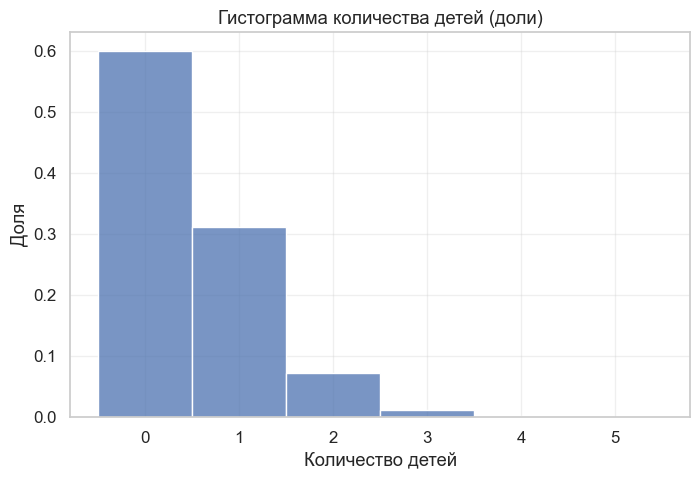

In [3]:
# 1. Анализ дискретных переменных

print("\nРаспределение количества детей")
print(df['num_children'].value_counts())
print(df['num_children'].value_counts(normalize=True))

# Гистограмма для дискретных переменных (визуализация распределения)
plt.figure(figsize=(8, 5))
sns.histplot(df['num_children'], discrete=True, stat='probability') # stat='probability' показывает долю
plt.title('Гистограмма количества детей (доли)')
plt.xlabel('Количество детей')
plt.ylabel('Доля')
plt.xticks(df['num_children'].unique()) # Устанавливаем метки для каждого значения
plt.show()


value_counts для возраста (неинформативно):
age
18.00    465
35.34     12
36.85     11
37.69     10
30.16     10
Name: count, dtype: int64


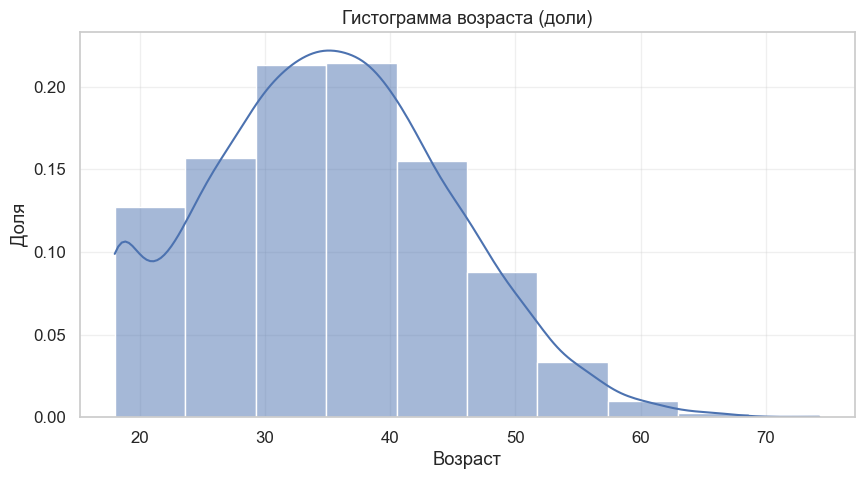

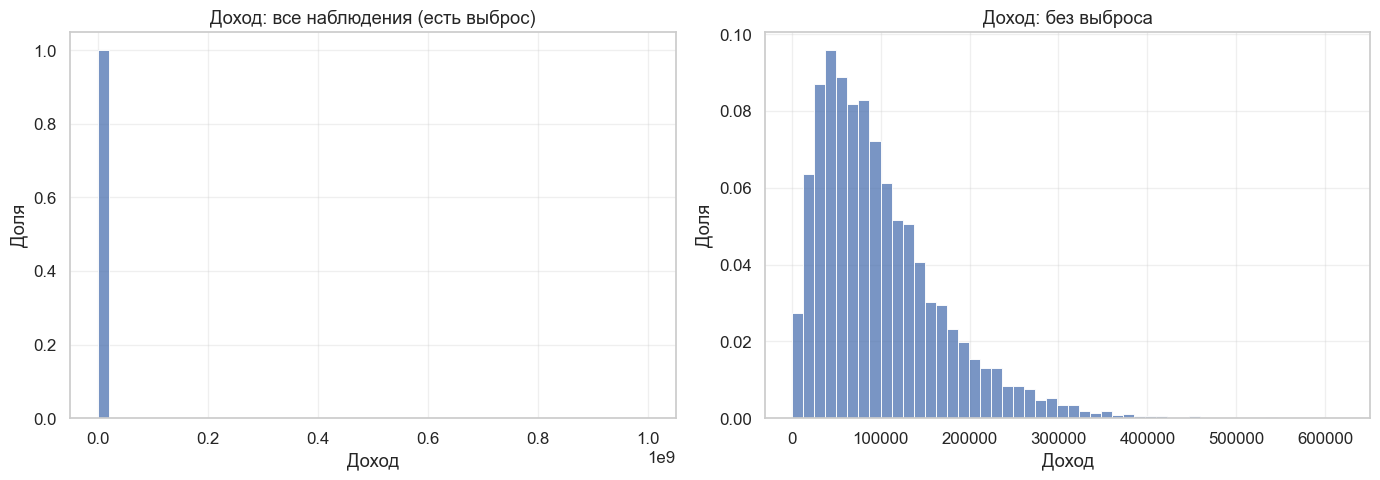


Распределение возраста по 10 бинам:
age_bin
0    1270
1    1565
2    2129
3    2145
4    1552
5     878
6     337
7      96
8      24
9       4
Name: count, dtype: int64


In [4]:
# 2. Анализ непрерывных переменных

print("\nvalue_counts для возраста (неинформативно):")
print(df['age'].value_counts().head())

# Гистограмма для непрерывных переменных - разбивает диапазон на интервалы (бины)
plt.figure(figsize=(10, 5))
sns.histplot(df['age'], bins=10, kde=True, stat='probability') # kde=True добавляет оценку плотности ядра
plt.title('Гистограмма возраста (доли)')
plt.xlabel('Возраст')
plt.ylabel('Доля')
plt.show()

# Один выброс в 1 млрд растягивает ось: на левом графике все наблюдения попадают в первый столбец
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['income'], bins=50, stat='probability', ax=axes[0])
axes[0].set_title('Доход: все наблюдения (есть выброс)')
sns.histplot(df['income'].iloc[1:], bins=50, stat='probability', ax=axes[1])
axes[1].set_title('Доход: без выброса')
for ax in axes:
    ax.set_xlabel('Доход')
    ax.set_ylabel('Доля')
plt.tight_layout()
plt.show()

# Разбиение непрерывной переменной на категории (бины) с помощью pd.cut
df['age_bin'] = pd.cut(df['age'], bins=10, labels=False, include_lowest=True)
print("\nРаспределение возраста по 10 бинам:")
print(df['age_bin'].value_counts().sort_index())

### Метрики

In [5]:
# 3. Метрики центральной тенденции

print("\n3. Метрики центральной тенденции:")
# Среднее
print(f"Средний возраст: {df['age'].mean():.2f}")
print(f"Среднее количество детей: {df['num_children'].mean():.2f}")
print(f"Средний доход: {df['income'].mean():.2f}")

# Проблема Билла Гейтса: Среднее чувствительно к выбросам

print(f"Средний доход без Билла Гейтса: {df.iloc[1:]['income'].mean():.2f}")
print(f"Средний доход с Биллом Гейтсом: {df['income'].mean():.2f}") # Среднее сильно исказилось

# Медиана
print(f"Медианное количество детей: {df['num_children'].median():.2f}")
print(f"Медианный доход без Билла Гейтса: {df.iloc[1:]['income'].median():.2f}")
print(f"Медианный доход с Биллом Гейтсом: {df['income'].median():.2f}") # Медиана осталась разумной

# Мода
print(f"\nМода количества детей: {df['num_children'].mode().tolist()}") # Может быть несколько мод
print(f"Мода возраста (для непрерывной, может быть неинформативно): {df['age'].mode().tolist()}") # Обычно бесполезна для непрерывных

# Квантили (процентили)

# Значение, ниже которого находится определенный процент наблюдений.
print(f"\n10-й процентиль дохода: {df['income'].quantile(0.10):.2f}")
print(f"90-й процентиль дохода: {df['income'].quantile(0.90):.2f}")

# Квартили - это 25-й, 50-й (медиана) и 75-й процентили
print(f"25-й процентиль (Q1) дохода: {df['income'].quantile(0.25):.2f}")
print(f"75-й процентиль (Q3) дохода: {df['income'].quantile(0.75):.2f}")

# 4. Метрики разброса
print("\n4. Метрики разброса:")
# Стандартное отклонение (STD). Как и среднее, чувствительно к выбросам: здесь Билл Гейтс ещё в данных
print(f"Стандартное отклонение дохода: {df['income'].std():.2f}")

# Среднее абсолютное отклонение (не путать с медианным абсолютным отклонением, которое тоже обозначают MAD)
income_mean = df['income'].mean()
mad_income = np.mean(np.abs(df['income'] - income_mean))
print(f"Среднее абсолютное отклонение дохода (MAD): {mad_income:.2f}")

# 5. Сводная статистика (describe)
print("\n5. Сводная статистика (describe):")
print(df['income'].describe()) # Включает количество, среднее, СКО, минимум, 25%, 50%, 75%, максимум


3. Метрики центральной тенденции:
Средний возраст: 35.17
Среднее количество детей: 0.51
Средний доход: 199577.63
Средний доход без Билла Гейтса: 99587.59
Средний доход с Биллом Гейтсом: 199577.63
Медианное количество детей: 0.00
Медианный доход без Билла Гейтса: 82976.22
Медианный доход с Биллом Гейтсом: 82976.29

Мода количества детей: [0]
Мода возраста (для непрерывной, может быть неинформативно): [18.0]

10-й процентиль дохода: 26969.15
90-й процентиль дохода: 194790.81
25-й процентиль (Q1) дохода: 47130.82
75-й процентиль (Q3) дохода: 134251.95

4. Метрики разброса:
Стандартное отклонение дохода: 9999254.28
Среднее абсолютное отклонение дохода (MAD): 211151.35

5. Сводная статистика (describe):
count    1.000000e+04
mean     1.995776e+05
std      9.999254e+06
min      7.313300e+02
25%      4.713082e+04
50%      8.297629e+04
75%      1.342520e+05
max      1.000000e+09
Name: income, dtype: float64


### Визуализации

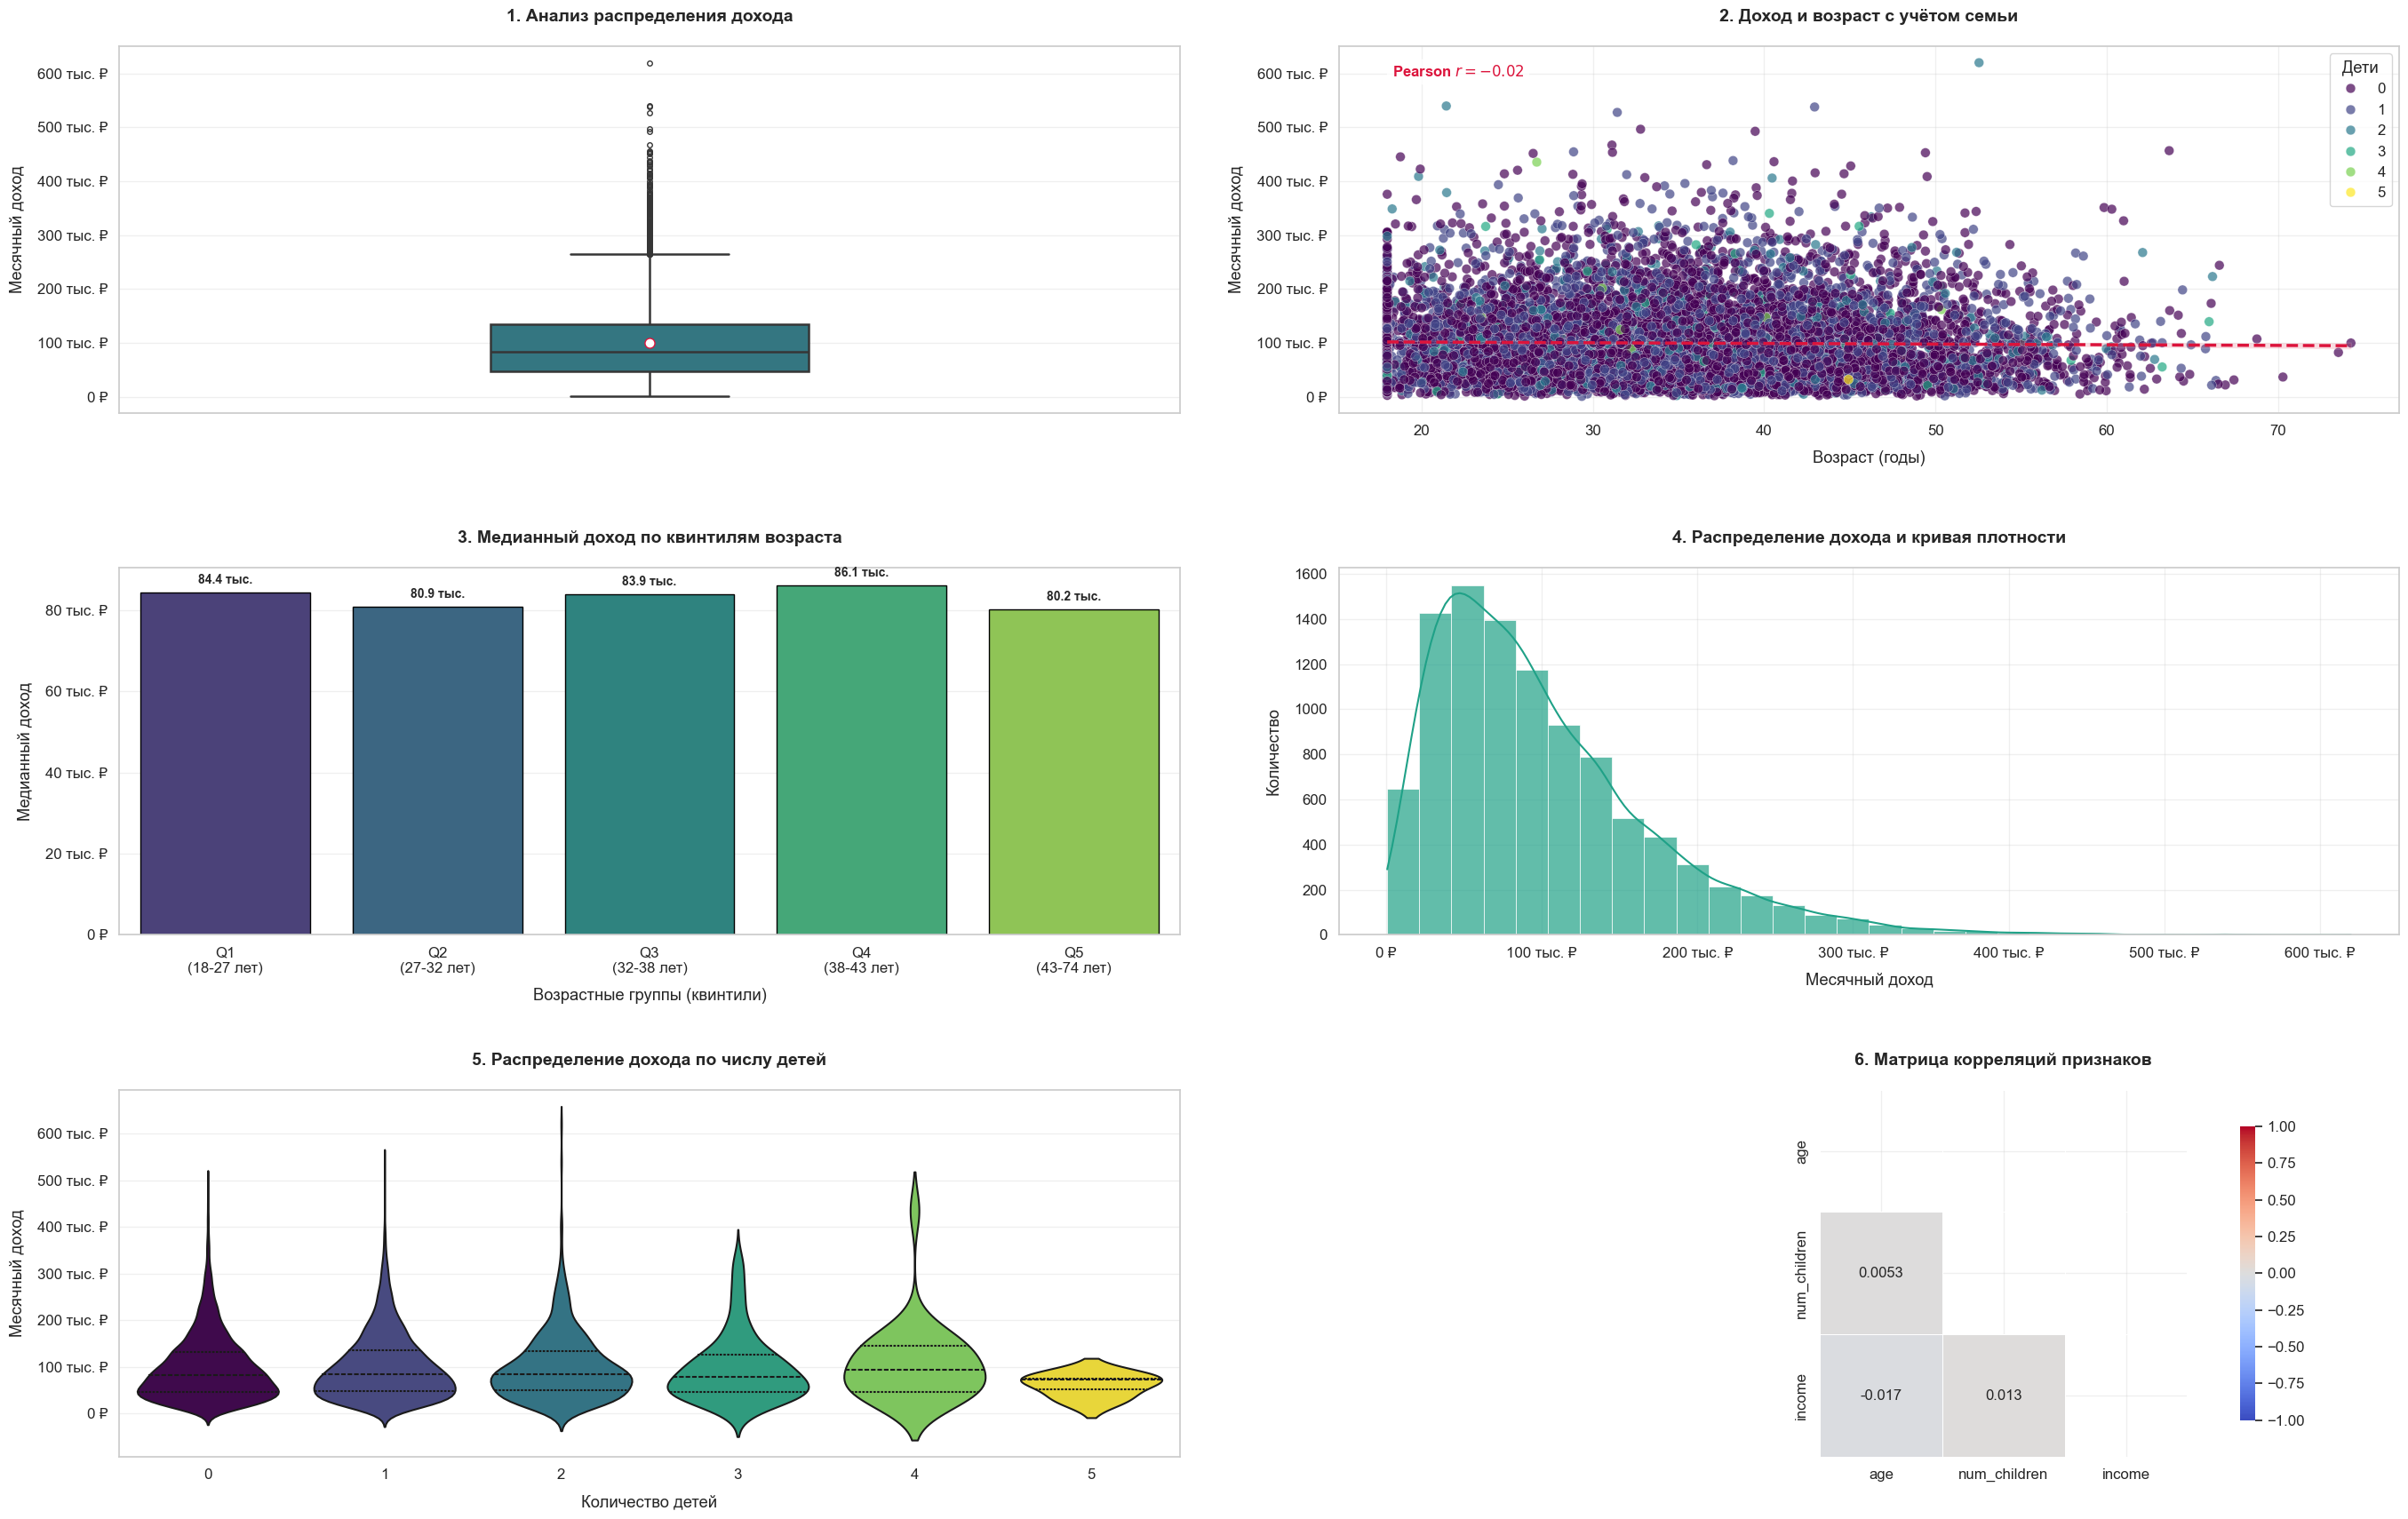


Дополнительная визуализация pairplot:


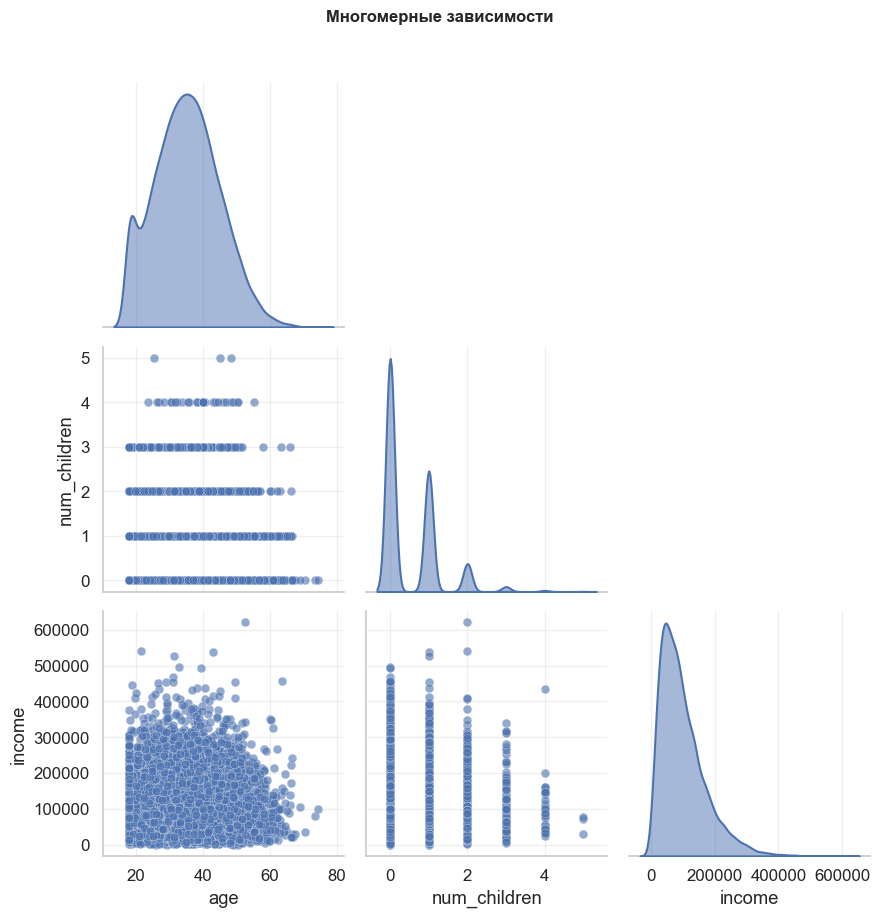

In [6]:
# Убираем выброс, иначе он сожмёт все графики, и создаём возрастные группы
df = df.iloc[1:].copy()

df['age_group_label'] = pd.qcut(df['age'], q=5, labels=[f'Q{i+1}\n({q.left:.0f}-{q.right:.0f} лет)'
                              for i, q in enumerate(pd.qcut(df['age'], q=5).cat.categories)])
df['age_group'] = pd.qcut(df['age'], q=5)


# Пользовательский форматтер валюты
def currency_formatter(x: float, pos: int) -> str:
    """Форматирует значение в валютный вид для подписей оси."""
    return f'{x / 1000:,.0f} тыс. ₽' if x >= 10000 else f'{x:,.0f} ₽'

# Создаём фигуру с подграфиками
fig, axes = plt.subplots(3, 2, figsize=(14*2, 6*3))  # 3 строки, 2 столбца
axes = axes.flatten()

# ---------- 1. Расширенная ящичная диаграмма ----------
sns.boxplot(
    y='income',
    data=df,
    width=0.3,
    fliersize=4,
    linewidth=1.8,
    color=palette[2],
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"crimson", "markersize":"8"},
    ax=axes[0]
)
axes[0].set_title('1. Анализ распределения дохода', pad=20, fontweight='bold', fontsize=14)
axes[0].set_ylabel('Месячный доход', labelpad=10)
axes[0].yaxis.set_major_formatter(FuncFormatter(currency_formatter))

# ---------- 2. Диаграмма рассеяния (scatterplot) с регрессией ----------
sns.scatterplot(
    x='age',
    y='income',
    hue='num_children',
    data=df,
    alpha=0.7,
    s=60,
    palette='viridis',
    edgecolor='white',
    linewidth=0.3,
    ax=axes[1]
)

# Линия регрессии
sns.regplot(
    x='age',
    y='income',
    data=df,
    scatter=False,
    ax=axes[1],
    color='crimson',
    line_kws={'linewidth':2.5, 'linestyle':'--'}
)

# Подпись коэффициента корреляции
r = df['age'].corr(df['income'])
axes[1].annotate(
    fr'Pearson $r={r:.2f}$',
    xy=(0.05, 0.95),
    xycoords='axes fraction',
    fontsize=12,
    fontweight='bold',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8),
    color='crimson',
    ha='left',
    va='top'
)

axes[1].set_title('2. Доход и возраст с учётом семьи', pad=20, fontweight='bold', fontsize=14)
axes[1].set_xlabel('Возраст (годы)', labelpad=10)
axes[1].set_ylabel('Месячный доход', labelpad=10)
axes[1].yaxis.set_major_formatter(FuncFormatter(currency_formatter))
axes[1].legend(title='Дети', bbox_to_anchor=(1, 1))

# ---------- 3. Улучшенный столбчатый график по квинтилям возраста ----------
medians = df.groupby('age_group_label', observed=True)['income'].median().reset_index()

sns.barplot(
    x='age_group_label',
    y='income',
    hue='age_group_label',
    legend=False,
    data=medians,
    palette='viridis',
    edgecolor='black',
    linewidth=1,
    ax=axes[2]
)

# Добавляем подписи значений
for p in axes[2].patches:
    axes[2].annotate(
        f"{p.get_height()/1000:,.1f} тыс.",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center', xytext=(0, 10),
        textcoords='offset points',
        fontsize=10,
        fontweight='bold'
    )

axes[2].set_title('3. Медианный доход по квинтилям возраста', pad=20, fontweight='bold', fontsize=14)
axes[2].set_xlabel('Возрастные группы (квинтили)', labelpad=10)
axes[2].set_ylabel('Медианный доход', labelpad=10)
axes[2].yaxis.set_major_formatter(FuncFormatter(currency_formatter))

# ---------- 4. Гистограмма с KDE ----------
sns.histplot(
    data=df,
    x='income',
    bins=30,
    kde=True,
    color=palette[3],
    edgecolor='white',
    linewidth=0.5,
    alpha=0.7,
    ax=axes[3]
)

axes[3].set_title('4. Распределение дохода и кривая плотности', pad=20, fontweight='bold', fontsize=14)
axes[3].set_xlabel('Месячный доход', labelpad=10)
axes[3].set_ylabel('Количество', labelpad=10)
axes[3].xaxis.set_major_formatter(FuncFormatter(currency_formatter))

# ---------- 5. Скрипичная диаграмма дохода по количеству детей ----------
sns.violinplot(
    x='num_children',
    y='income',
    hue='num_children',
    legend=False,
    data=df,
    palette='viridis',
    inner='quartile',
    linewidth=1.5,
    saturation=0.8,
    ax=axes[4]
)

axes[4].set_title('5. Распределение дохода по числу детей', pad=20, fontweight='bold', fontsize=14)
axes[4].set_xlabel('Количество детей', labelpad=10)
axes[4].set_ylabel('Месячный доход', labelpad=10)
axes[4].yaxis.set_major_formatter(FuncFormatter(currency_formatter))

# ---------- 6. Тепловая карта корреляций (по исходным числовым данным) ----------
corr_df = df[['age', 'num_children', 'income']].corr()
mask = np.triu(np.ones_like(corr_df, dtype=bool))
sns.heatmap(
    corr_df,
    mask=mask,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 12},
    ax=axes[5]
)
axes[5].set_title('6. Матрица корреляций признаков', pad=20, fontweight='bold', fontsize=14)

# Настраиваем расположение
plt.tight_layout(pad=3.0)
plt.show()

# ---------- 7. Парный график (pairplot) — выводим отдельно ----------
print("\nДополнительная визуализация pairplot:")
g = sns.pairplot(
    df[['age', 'num_children', 'income']],
    diag_kind='kde',
    plot_kws={'alpha':0.6, 's':40, 'edgecolor':'white', 'linewidth':0.3},
    diag_kws={'fill':True, 'alpha':0.5, 'linewidth':1.5},
    corner=True,
    height=3  # Компактные отдельные графики парного графика (pairplot)
)
g.fig.suptitle('Многомерные зависимости', y=1.02, fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

### Задачки

#### 1. Оценить вероятность выпадения 6 на игральном кубике

##### Решение

In [7]:
dice_faces = list(range(1, 7)) # Грани кубика: от 1 до 6
n_rolls = 100_000 # Количество бросков для симуляции

# Выполняем броски
rolls = np.random.choice(dice_faces, size=n_rolls)

# Оцениваем вероятность выпадения шестерки
prob_six_simulated = np.mean(rolls == 6)
print(f"Оценка вероятности выпадения шестерки (симуляция): {prob_six_simulated:.4f}")

Оценка вероятности выпадения шестерки (симуляция): 0.1654


Точный ответ: $1/6 \approx 0.1667$.

#### 2. Парадокс дней рождения

Определить вероятность того, что в группе из 23 человек хотя бы у двух людей совпадёт день рождения.

##### Решение

In [8]:
n_people = 23 # Количество человек в группе
n_simulations_bd = 10000 # Количество симуляций групп
n_days_in_year = 365 # Количество дней в году (игнорируем високосный год)

coincidences = []
for _ in range(n_simulations_bd):
    # Генерируем дни рождения для n_people в диапазоне n_days_in_year с возвращением
    birthdays = np.random.randint(0, n_days_in_year, n_people)
    # Проверяем, есть ли совпадения (т.е. количество уникальных дней рождения меньше, чем количество людей)
    has_coincidence = len(np.unique(birthdays)) < n_people
    coincidences.append(has_coincidence)

prob_coincidence_simulated = np.mean(coincidences)
print(f"Оценка вероятности совпадения дней рождения в группе из {n_people} человек: {prob_coincidence_simulated:.4f}")

Оценка вероятности совпадения дней рождения в группе из 23 человек: 0.5067


Точный ответ: $1 - \dfrac{365 \cdot 364 \cdots 343}{365^{23}} \approx 0.5073$. Вероятность больше 1/2 уже при 23 людях, потому что считаются совпадения по всем $\binom{23}{2} = 253$ парам, а не только с одним конкретным человеком.

#### 3. Задача об экзамене

Студент выучил 20 билетов из 30. Ему выгоднее идти первым или вторым?

##### Решение

In [9]:
total_tickets = 30
learned_tickets_count = 20
learned_tickets = set(range(1, learned_tickets_count + 1)) # Билеты, которые знает студент (допустим 1-20)
all_tickets = list(range(1, total_tickets + 1)) # Все билеты

n_exams = 100_000 # Количество симуляций экзаменов

# Вариант 1: Студент идет первым
first_student_success = []
for _ in tqdm(range(n_exams), desc='Считаем первый случай'):
    shuffled_tickets = random.sample(all_tickets, total_tickets) # Перемешиваем билеты
    pulled_ticket = shuffled_tickets[0] # Первый билет
    first_student_success.append(pulled_ticket in learned_tickets)
prob_first_student = np.mean(first_student_success)
print(f"Вероятность вытянуть выученный билет, если студент идет первым: {prob_first_student:.4f}")

# Вариант 2: Студент идет вторым
second_student_success = []
for _ in tqdm(range(n_exams), desc='Считаем второй случай'):
    shuffled_tickets = random.sample(all_tickets, total_tickets) # Перемешиваем билеты
    # Первый билет откладывается, поэтому второй студент выбирает из оставшихся
    pulled_ticket_second_person = shuffled_tickets[1] # Второй билет
    second_student_success.append(pulled_ticket_second_person in learned_tickets)
prob_second_student = np.mean(second_student_success)
print(f"Вероятность вытянуть выученный билет, если студент идет вторым: {prob_second_student:.4f}")

Вероятность вытянуть выученный билет, если студент идет первым: 0.6661


Вероятность вытянуть выученный билет, если студент идет вторым: 0.6664


Ответ: разницы нет. Вероятность равна $20/30 = 2/3$ при любой очерёдности: до вытягивания все позиции в перемешанной стопке билетов равноправны.

#### 4. Задача о такси

В городе встречаются зеленые и синие такси в соотношении 85:15. Свидетель верно определяет цвет в 80% случаев.
Какова вероятность, что такси окажется действительно синим, если свидетель сказал, что оно синее?

##### Решение

In [10]:
n_incidents = 100_000 # Количество симуляций инцидентов

actual_colors = []
witness_statements = []

for _ in range(n_incidents):
    # Генерируем реальный цвет такси: 15% синих (1), 85% зеленых (0)
    actual_taxi_color = np.random.choice([0,1], p=[0.85, 0.15]) # 0 - зеленое, 1 - синее
    actual_colors.append(actual_taxi_color)

    # Моделируем показания свидетеля
    if np.random.rand() < 0.8: # Свидетель верно определяет цвет в 80% случаев
        witness_says = actual_taxi_color
    else: # Ошибается в 20% случаев
        witness_says = 1 - actual_taxi_color # Говорит противоположный цвет
    witness_statements.append(witness_says)

# Создаем DataFrame для анализа
taxi_df = pd.DataFrame({'actual_color': actual_colors, 'witness_says': witness_statements})

# Фильтруем случаи, когда свидетель сказал, что такси синее (witness_says == 1)
witness_said_blue = taxi_df[taxi_df['witness_says'] == 1]
# Из этих случаев, какая доля была реально синей (actual_color == 1)
prob_actual_blue_given_witness_blue = np.mean(witness_said_blue['actual_color'] == 1)

print(f"Вероятность того, что такси действительно синее, если свидетель сказал, что оно синее: {prob_actual_blue_given_witness_blue:.4f}")

Вероятность того, что такси действительно синее, если свидетель сказал, что оно синее: 0.4130


Точный ответ по формуле Байеса: $\dfrac{0.15 \cdot 0.8}{0.15 \cdot 0.8 + 0.85 \cdot 0.2} \approx 0.41$. Несмотря на надёжного свидетеля, такси скорее зелёное: синих машин слишком мало, и базовую частоту нельзя игнорировать.

#### 5. Задача о русской рулетке

Револьвер с 6 гнездами, заряжены 2 патрона подряд. Первый игрок крутит барабан, стреляет и остаётся жив. Что выгоднее второму игроку: покрутить барабан перед выстрелом или сразу выстрелить?

##### Решение

In [11]:
def rotate_chamber(chamber: list[int]) -> list[int]:
    """Сдвигает барабан револьвера на одну позицию вперёд без дополнительного вращения."""
    return chamber[1:] + chamber[:1]

def spin_chamber(chamber: list[int]) -> list[int]:
    """Вращает барабан на случайное число позиций."""
    k = random.randint(0, len(chamber) - 1)
    return chamber[k:] + chamber[:k]


# — — — Главная функция симуляции — — —
def simulate(n_games: int = 1_000_000, spin_second: bool = True) -> float:
    """Моделирует русскую рулетку и оценивает шанс гибели второго игрока.

    Args:
        n_games: Количество симулированных партий.
        spin_second: Признак того, что второй игрок повторно крутит барабан.

    Returns:
        Оценка условной вероятности смерти второго игрока.
    """
    deaths, trials = 0, 0

    for _ in tqdm(range(n_games)):

        chamber = [1, 1, 0, 0, 0, 0] # два подряд идущих патрона

        chamber = spin_chamber(chamber) # первый игрок крутит барабан и стреляет
        if chamber[0] == 1:                # первый погиб – нас не интересует -> начинаем новую партию
            continue

        # первый выжил, учитываем такую партию
        trials += 1

        # после выстрела барабан переходит к следующей камере
        chamber = rotate_chamber(chamber)

        # решение второго игрока
        if spin_second:
            chamber = spin_chamber(chamber)

        if chamber[0] == 1: # выстрел второго игрока
            deaths += 1

    return deaths / trials


N = 1_000_000   # число партий (первый игрок выживает примерно в 2/3 из них)

p_spin     = simulate(N, spin_second=True)
p_no_spin  = simulate(N, spin_second=False)

print(f"\nВероятность смерти, если ПОВТОРНО крутить барабан : {p_spin:.4f}")
print(f"Вероятность смерти, если НЕ крутить барабан      : {p_no_spin:.4f}")


Вероятность смерти, если ПОВТОРНО крутить барабан : 0.3330
Вероятность смерти, если НЕ крутить барабан      : 0.2506


Ответ: крутить барабан невыгодно. Если крутить, вероятность гибели равна $2/6 = 1/3$. Если не крутить, то первый игрок попал в одно из 4 пустых гнёзд, и только за последним из них идёт патрон: вероятность равна $1/4$.

## Основная часть: Бутстреп (Bootstrap)

**Бутстреп (bootstrap)** – это статистический метод, позволяющий оценивать стандартные ошибки, строить доверительные интервалы и проверять гипотезы для произвольных статистических функционалов. Он особенно полезен, когда нет простой теоретической формулы для стандартной ошибки метрики или формула требует того, что трудно оценить: например, стандартная ошибка квантиля зависит от неизвестной плотности распределения.

Классическая статистика часто опирается на асимптотические результаты: большой размер выборки $n$ и определённые свойства данных (например, нормальность или гомоскедастичность). В реальной жизни эти условия выполняются не всегда, а для сложных характеристик (квантили, отношения метрик, коэффициенты сложных моделей) готовые формулы стандартных ошибок неудобны или неизвестны. Бутстреп приходит на помощь именно в таких случаях.

**Основной принцип** бутстрепа заключается в том, что вместо генерации данных из истинного, но неизвестного распределения мы используем эмпирическую функцию распределения (ЭФР), построенную по имеющейся выборке, как его оценку. В каждой точке ЭФР является несмещённой оценкой истинной функции распределения и сходится к ней при увеличении размера выборки.

**Важно:** бутстреп не волшебство и тоже асимптотический метод. Он не создаёт новой информации, не спасает при очень маленькой выборке и опирается на то, что выборка хорошо представляет распределение. Случаи, когда он ломается, разобраны в конце раздела про наивный бутстреп.

### Эмпирическая Функция Распределения (ЭФР)

**ЭФР (Empirical Distribution Function)** — это оценка истинной функции распределения, которая получается из имеющейся выборки. Если у нас есть выборка из $n$ независимых и одинаково распределенных (i.i.d.) случайных величин $X_1, X_2, \ldots, X_n$, то ЭФР $F_n(x)$ определяется как доля наблюдений в выборке, которые меньше или равны $x$: $$ F_n(x) = \frac{1}{n} \sum_{i=1}^{n} \mathbf{1}\left[{X_i \le x}\right] $$где $\mathbf{1}\left[{X_i \le x}\right]$ — это индикаторная функция, равная 1, если $X_i \le x$, и 0 в противном случае. По сути, ЭФР — это функция распределения дискретной случайной величины, где каждому наблюдению $X_i$ из исходной выборки присваивается вероятность $1/n$.

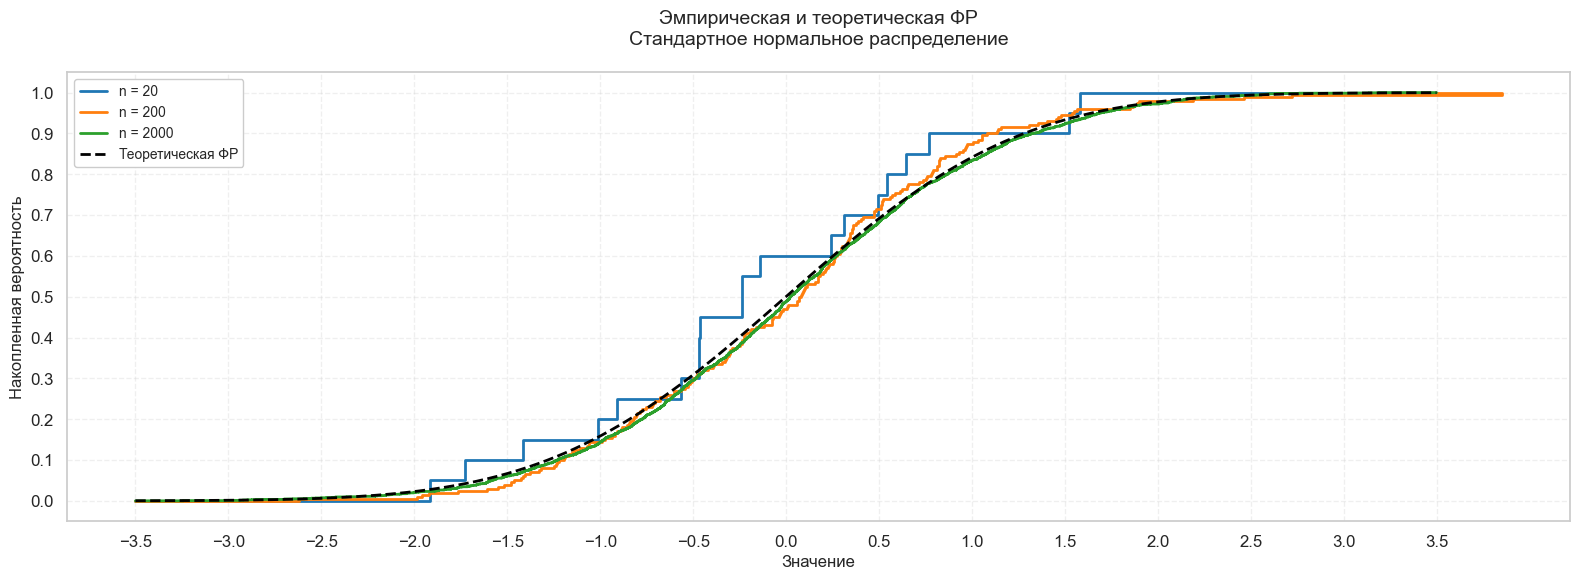

In [12]:
def plot_ecdf(values: np.ndarray, label: str, xlim: tuple[float, float], color: str | None = None) -> None:
    """Строит эмпирическую функцию распределения (ECDF) для набора значений.

    Args:
        values: Массив наблюдений.
        label: Подпись для легенды графика.
        xlim: Границы оси X в формате (минимум, максимум).
        color: Цвет линии ECDF.
    """
    X_ = np.sort(np.unique(values))
    Y_ = np.array([np.mean(values <= x) for x in X_])

    # Формируем ступенчатые точки для ECDF
    X = np.concatenate([[xlim[0]], np.repeat(X_, 2), [xlim[1]]])
    Y = np.concatenate([[0, 0], np.repeat(Y_, 2)])

    plt.plot(X, Y, label=label, color=color, linewidth=2)

# Параметры
np.random.seed(42)  # Для воспроизводимости
sample_sizes = [20, 200, 2000]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
x_limits = [-3.5, 3.5]

# Генерация данных и построение ECDF
plt.figure(figsize=(16, 6), dpi=100)

for size, color in zip(sample_sizes, colors):
    values = np.random.normal(0, 1, size=size)
    plot_ecdf(values, f'n = {size}', x_limits, color)

# Строим теоретическую ФР
X = np.linspace(x_limits[0], x_limits[1], 1000)
Y = stats.norm.cdf(X)
plt.plot(X, Y, '--', color='black', label='Теоретическая ФР', linewidth=2)

# Настраиваем график
plt.title('Эмпирическая и теоретическая ФР\nСтандартное нормальное распределение',
          fontsize=14, pad=20)
plt.xlabel('Значение', fontsize=12)
plt.ylabel('Накопленная вероятность', fontsize=12)
plt.legend(fontsize=10, framealpha=1)
plt.grid(True, linestyle='--', alpha=0.3)

# Настраиваем подписи и расположение
plt.xticks(np.arange(x_limits[0], x_limits[1]+0.5, 0.5))
plt.yticks(np.arange(0, 1.1, 0.1))

plt.tight_layout()
plt.show()

На графике видно, что при увеличении размера выборки ЭФР лучше приближает истинную функцию распределения. Если увеличить размер выборки до нескольких тысяч, то ЭФР визуально будет сложно отличить от истинной функции распределения.

Строгое обоснование этого даёт следующая теорема.

**[Теорема Гливенко-Кантелли](https://ru.wikipedia.org/wiki/Теорема_Гливенко_—_Кантелли)**:


Пусть $X_1, \ldots, X_n, \ldots$ - бесконечная выборка из распределения, задаваемого функцией распределения $F$. Пусть $\hat{F}$ - выборочная функция распределения, построенная на первых $n$ элементах выборки. Тогда

$$
\lim_{n\to\infty} \sup_{x\in\mathbb{R}} \left|\hat{F}(x) - F(x)\right| = 0 \quad \text{почти наверное}
$$

Так как нам известно, что ЭФР "хорошо" приближает истинную ФР, давайте генерировать данные из неё и с их помощью оценивать разброс статистик и строить доверительные интервалы.

### Наивный Бутстреп

**Наивный бутстреп** — это самый базовый и широко используемый вариант бутстрепа. Он используется для оценки стандартной ошибки произвольной статистики и построения доверительных интервалов, особенно когда нет простой аналитической формулы для этих величин.

**Для чего используется:** Предположим, мы хотим оценить стандартную ошибку 90% квантиля времени доставки заказа. Для среднего есть простая формула $s/\sqrt{n}$, а асимптотическая формула для квантиля содержит неизвестную плотность распределения в точке квантиля. Наивный бутстреп позволяет обойти это ограничение.

**Предположения:**

1. Предполагается, что исходные данные являются независимыми и одинаково распределенными (i.i.d.). Если данные зависимы или имеют сложную природу, бутстреп может давать плохие приближения истинного распределения, если это не учитывать при генерации подвыборок. Для таких данных ресэмплируют не отдельные наблюдения, а целые блоки: пользователей (кластерный бутстреп) или отрезки временного ряда (блочный бутстреп).
2. **Размер N:** Бутстреп тоже требует достаточно большого $n$ для получения точных результатов: выборка должна хорошо представлять распределение.


**Преимущества и Недостатки:**

* **Универсальность:** Позволяет оценивать свойства распределений практически любых статистик.
* **Простота:** Не требует аналитических формул для стандартных ошибок.
* **Вычислительная затратность:** Основной недостаток — это вычислительно трудоемкая процедура, которая может занимать много времени при больших объемах данных.

**Алгоритм:**
1. Сгенерировать бутстреп-выборку
  
   - Выбрать $n$ элементов из исходной выборки $X_1, \ldots, X_n$ случайным образом с возвращением.
   - Это эквивалентно генерации подвыборки размера $n$, где каждый элемент исходной выборки имеет вероятность $\frac{1}{n}$ быть выбранным.

2. Вычислить статистику
   - Посчитать интересующую статистику $S$ для этой бутстреп-выборки.

3. Повторить шаги 1 и 2

   - Повторить шаги 1 и 2 большое количество раз (рекомендуется от 1000 до 10000 раз), получая $B$ значений статистики $S^*_1, \ldots, S^*_B$.

4. Посчитать стандартную ошибку или ДИ

**Важные замечания:**
1. Сэмплинг должен быть обязательно с повторениями;
2. Количество бутстреп-итераций $B$ должно быть довольно большим, чтобы снизить ошибку Монте-Карло. Близость ЭФР к истинной функции распределения определяется размером выборки $n$, и увеличение $B$ её не улучшит;
3. Бутстреп-статистика должна считаться именно на $n$ элементах выборки, чтобы её разброс соответствовал разбросу оцениваемой статистики.

**Подсчёты**

**Оценка стандартной ошибки**

Стандартную ошибку статистики можно оценить как стандартное отклонение набора бутстреп-значений $S^*_1, \ldots, S^*_B$:

  $$
  \text{se}(\hat{S}) \approx \text{std}(S^*_1, \ldots, S^*_B)
  $$
  

**Доверительный интервал**

1. **Перцентильный доверительный интервал**
  
  Для построения $100\times (1-\alpha)\%$ доверительного интервала (ДИ) на основе перцентильного метода необходимо отбросить долю $\alpha/2$ самых маленьких и долю $\alpha/2$ самых больших значений из отсортированного списка бутстреп-статистик.
$$
  \text{ДИ} = \left[ S^*_{(\alpha/2 \cdot B)} \text{ ; } S^*_{( (1-\alpha/2) \cdot B )} \right]
  \quad \text{где } S^*_{(k)} — \text{k-е значение в отсортированном списке бутстреп-статистик}
$$

  Границы перцентильного ДИ — это реальные значения бутстреп-статистики, поэтому они **никогда не выходят за пределы допустимых значений** (например, доля не станет отрицательной). Но при скошенном распределении статистики или смещении оценки интервал может оказаться смещённым, и его покрытие будет ниже заявленного.

2. **Нормальный Доверительный Интервал**
  
  Нормальный доверительный интервал основан на предположении, что распределение статистики приблизительно нормально, особенно когда данных много (когда такое можно предполагать?). Для $100\times (1-\alpha)\%$ доверительного интервала, нормальный ДИ вычисляется как: $$ \text{ДИ} = \left[ \hat{S} - z_{1-\alpha/2} \cdot \text{se}(\hat{S}) \text{ ; } \hat{S} + z_{1-\alpha/2} \cdot \text{se}(\hat{S}) \right] $$ где:
  
  * $\hat{S}$ — точечная оценка статистики по исходным данным.
  * $\text{se}(\hat{S})$ — стандартная ошибка статистики, полученная с помощью бутстрепа.
  * $z_{1-\alpha/2}$ — квантиль стандартного нормального распределения для заданного уровня значимости $\alpha$.

  Этот метод хорошо работает, когда распределение статистики близко к нормальному. Если распределение несимметрично, нормальный ДИ может давать нереалистичные границы (например, отрицательные значения для изначально положительных метрик).

3. **Центральный (Pivotal) Доверительный Интервал**

  Центральный (пивотальный, он же basic) доверительный интервал на первый взгляд может показаться нелогичным, но его легко вывести. Он основан на предположении, что распределение разности $S^* - \hat{S}$ похоже на распределение разности $\hat{S} - S$, где $S$ — истинное значение.

  Для $100 \times (1-\alpha)\%$ доверительного интервала, центральный ДИ вычисляется как:

  $$
  \text{ДИ} = \left[ 2\hat{S} - S^*_{((1-\alpha/2) \cdot B)}, 2\hat{S} - S^*_{(\alpha/2 \cdot B)} \right]
  $$

  где:
  * $\hat{S}$ — точечная оценка статистики по исходным данным
  * $S^*_{(k)}$ — $k$-е значение в отсортированном списке бутстреп-статистик

  В отличие от перцентильного, этот интервал может выходить за пределы допустимых значений: при скошенном распределении его границы отражаются относительно $\hat{S}$ и уходят в сторону, где бутстреп-распределение имеет почти нулевую плотность.


======================== Результаты ========================
• Истинный 90% квантиль: 115.63 минут
• Точечная оценка 90% квантиля: 116.11 минут
• Стандартная ошибка (бутстреп): 1.64
• Нормальный 95% ДИ: (112.90, 119.32)
• Перцентильный 95% ДИ: (113.19, 118.95)
• Центральный 95% ДИ: (113.27, 119.04)


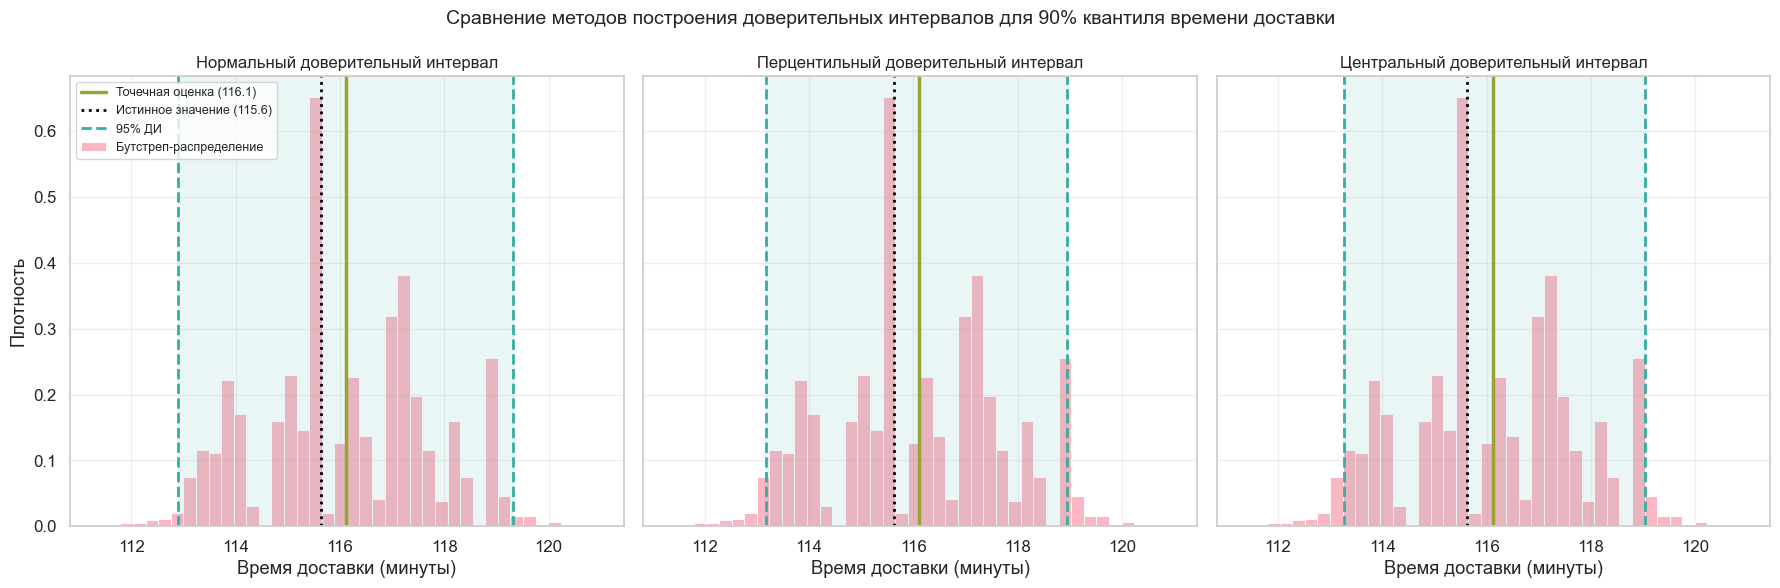

In [13]:
# ======================
# 1. Функции для расчета CI
# ======================

def calculate_standard_error(bootstrap_stats: np.ndarray) -> float:
    """Вычисляет стандартную ошибку по бутстреп-статистикам."""
    return float(np.std(bootstrap_stats, ddof=1))

def get_normal_ci(bootstrap_stats: np.ndarray, point_estimate: float, alpha: float) -> tuple[float, float]:
    """Строит нормальный доверительный интервал."""
    z = stats.norm.ppf(1 - alpha / 2)
    se = calculate_standard_error(bootstrap_stats)
    left = point_estimate - z * se
    right = point_estimate + z * se
    return float(left), float(right)

def get_percentile_ci(bootstrap_stats: np.ndarray, alpha: float) -> tuple[float, float]:
    """Строит перцентильный доверительный интервал."""
    left, right = np.quantile(bootstrap_stats, [alpha / 2, 1 - alpha / 2])
    return float(left), float(right)

def get_pivotal_ci(bootstrap_stats: np.ndarray, point_estimate: float, alpha: float) -> tuple[float, float]:
    """Строит центральный (пивотальный) доверительный интервал."""
    left = 2 * point_estimate - np.quantile(bootstrap_stats, 1 - alpha / 2)
    right = 2 * point_estimate - np.quantile(bootstrap_stats, alpha / 2)
    return float(left), float(right)

# ======================
# 2. Подготовка данных
# ======================
np.random.seed(42)
n = 1000
mean_delivery, std_delivery = 90, 20
values = np.clip(np.random.normal(mean_delivery, std_delivery, n), 0, None)

# Истинное значение (данные синтетические, поэтому мы его знаем) и точечная оценка
true_quantile = stats.norm.ppf(0.9, mean_delivery, std_delivery)
quantile_estimate = np.quantile(values, 0.9)

# Параметры бутстрепа
B = 10000
alpha = 0.05
confidence_level = round(100 * (1 - alpha))

# Генерация бутстреп-статистик
bootstrap_quantiles = np.array([
    np.quantile(np.random.choice(values, n, replace=True), 0.9)
    for _ in tqdm(range(B), desc='Генерация бутстреп-выборок')
])

# Расчет стандартной ошибки
std_error = calculate_standard_error(bootstrap_quantiles)

# ======================
# 3. Расчет доверительных интервалов
# ======================
normal_ci = get_normal_ci(bootstrap_quantiles, quantile_estimate, alpha)
percentile_ci = get_percentile_ci(bootstrap_quantiles, alpha)
pivotal_ci = get_pivotal_ci(bootstrap_quantiles, quantile_estimate, alpha)

# ======================
# 4. Вывод результатов
# ======================
print(f"\n{' Результаты ':=^60}")
print(f"• Истинный 90% квантиль: {true_quantile:.2f} минут")
print(f"• Точечная оценка 90% квантиля: {quantile_estimate:.2f} минут")
print(f"• Стандартная ошибка (бутстреп): {std_error:.2f}")
print(f"• Нормальный {confidence_level}% ДИ: ({normal_ci[0]:.2f}, {normal_ci[1]:.2f})")
print(f"• Перцентильный {confidence_level}% ДИ: ({percentile_ci[0]:.2f}, {percentile_ci[1]:.2f})")
print(f"• Центральный {confidence_level}% ДИ: ({pivotal_ci[0]:.2f}, {pivotal_ci[1]:.2f})")
print("=" * 60)

# ======================
# 5. Визуализация
# ======================
palette = sns.color_palette("husl", 4)
intervals = {'Нормальный': normal_ci, 'Перцентильный': percentile_ci, 'Центральный': pivotal_ci}

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
for ax, (name, (left, right)) in zip(axes, intervals.items()):
    # Гистограмма вместо KDE: выборочный квантиль принимает лишь несколько значений рядом с точкой
    # оценки, и KDE нарисовал бы несуществующие «горбы»
    sns.histplot(bootstrap_quantiles, bins=40, stat='density', color=palette[0], alpha=0.5, ax=ax,
                 label='Бутстреп-распределение')
    ax.axvline(quantile_estimate, color=palette[1], linewidth=2.5, label=f'Точечная оценка ({quantile_estimate:.1f})')
    ax.axvline(true_quantile, color='black', linestyle=':', linewidth=2, label=f'Истинное значение ({true_quantile:.1f})')
    ax.axvline(left, color=palette[2], linestyle='--', linewidth=2, label=f'{confidence_level}% ДИ')
    ax.axvline(right, color=palette[2], linestyle='--', linewidth=2)
    ax.axvspan(left, right, color=palette[2], alpha=0.1)
    ax.set_title(f'{name} доверительный интервал', fontsize=12)
    ax.set_xlabel('Время доставки (минуты)')
    ax.set_ylabel('Плотность')
axes[0].legend(loc='upper left', fontsize=9)

plt.suptitle('Сравнение методов построения доверительных интервалов для 90% квантиля времени доставки', fontsize=14)
plt.tight_layout()
plt.show()


Распределение здесь симметричное, а выборка большая, поэтому все три интервала почти совпадают. Различия проявляются на скошенных статистиках и малых выборках.

**Когда наивный бутстреп не работает**

Бутстреп опирается на то, что статистика плавно зависит от распределения и её распределение приближается к нормальному или другому предельному закону с той же скоростью, что и в исходной задаче. Это выполняется не всегда:

* **Экстремальные статистики** (минимум, максимум, очень высокие квантили). Бутстреп-выборка не может выйти за границы исходной, поэтому распределение максимума получается вырожденным (см. код ниже).
* **Тяжёлые хвосты.** Если дисперсия бесконечна, бутстреп среднего несостоятелен. Если она конечна, но хвост тяжёлый, на обычных размерах выборок покрытие ДИ заметно ниже заявленного.
* **Зависимые данные.** Заказы одного пользователя или соседние точки временного ряда нельзя ресэмплировать по отдельности: разброс будет занижен. Нужен кластерный или блочный бутстреп.

Проверим первый пункт: в бутстреп-выборку максимум исходной выборки попадает с вероятностью $1 - (1 - 1/n)^n \to 1 - 1/e \approx 0.632$, поэтому $\max^* = \max$ примерно в 63% бутстреп-выборок при любом $n$.

In [14]:
np.random.seed(42)
n = 1000
sample = np.random.uniform(0, 1, n)
bootstrap_maxima = np.array([np.random.choice(sample, n, replace=True).max() for _ in range(5000)])

print(f"Доля бутстреп-выборок, где max* = max: {np.mean(bootstrap_maxima == sample.max()):.3f}")
print(f"Теоретический предел 1 - 1/e:          {1 - 1 / np.e:.3f}")

Доля бутстреп-выборок, где max* = max: 0.632
Теоретический предел 1 - 1/e:          0.632


### Бутстреп t-статистики

**Бутстреп t-статистики** – это модификация бутстрепа, которая стремится улучшить точность доверительных интервалов, особенно когда распределение статистики не является идеально нормальным или когда размер выборки не очень велик. Она использует аналогию с классической t-статистикой, но заменяет неизвестные параметры их бутстреп-оценками.

**Для чего используется:** Этот метод применяется для построения доверительных интервалов, и он сходится к истинной вероятности покрытия быстрее, чем наивный бутстреп. Это означает, что для достижения той же точности доверительного интервала требуется меньший размер выборки N. Однако его использование требует наличия формулы для стандартной ошибки оцениваемой статистики. Если такой формулы нет, приходится прибегать к методу «бутстреп в бутстрепе» (двойной бутстреп) для оценки стандартной ошибки (о нём будет рассказано дальше).

**Преимущества и Недостатки:**

* **Высокая точность:** Обеспечивает более высокую точность доверительных интервалов по сравнению с наивным бутстрепом, особенно для ненормально распределенных статистик, так как быстрее приближает фактическую вероятность покрытия к заказанной.
* **Требует формулу для стандартной ошибки:** Главный недостаток — необходимость аналитической формулы для стандартной ошибки статистики. Если такой формулы нет, метод не применим без использования двойного бутстрепа.

**Алгоритм:**

1. Вычислить точечную оценку и её стандартную ошибку:
    
    По исходным данным вычислить точечную оценку статистики $\hat{S}$ и её стандартную ошибку $\text{se}(\hat{S})$.

2. Генерировать бутстреп-выборки: Повторить $B$ раз:

   * Сгенерировать бутстреп-выборку $X^*$.
   * Для каждой бутстреп-выборки вычислить статистику $\hat{S}^*$.
   * Вычислить бутстреп-аналог t-статистики:
  
    Если доступна аналитическая формула для стандартной ошибки, то для каждой бутстреп-выборки можно вычислить бутстреп-аналог t-статистики:
  
    $$
    t^* = \frac{\hat{S}^* - \hat{S}}{\text{se}^*(\hat{S}^*)}
    \quad \text{ где } \text{se}^*(\hat{S}^*) \text{ — это оценка стандартной ошибки статистики, вычисленная по бутстреп-выборке } X^*
    $$

3. Построить доверительный интервал:

    Вместо использования квантилей стандартного нормального распределения (как в нормальном ДИ), используются эмпирические квантили распределения $t^*$. $100 \times (1-\alpha)\%$ ДИ для параметра $S$:
  
  $$ \text{ДИ} = \left[ \hat{S} - t^*_{( (1-\alpha/2) \cdot B )} \cdot \text{se}(\hat{S}) \text{ ; } \hat{S} - t^*_{(\alpha/2 \cdot B)} \cdot \text{se}(\hat{S}) \right] $$


============== Результаты бутстрепа ==============
• Оценка среднего по выборке: 90.39
• Аналитическая стандартная ошибка: 0.62
• 95% доверительный интервал: (89.15, 91.58)


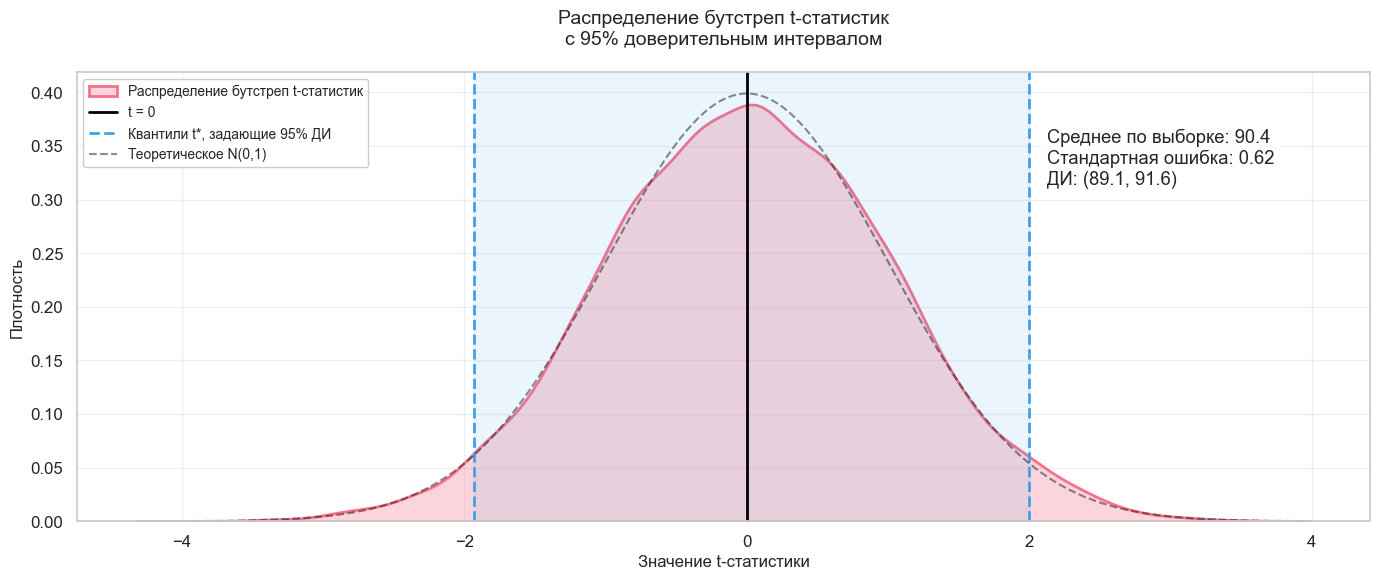

In [15]:
# Бутстреп-доверительные интервалы для среднего с аналитической стандартной ошибкой

# Настройки
np.random.seed(42)  # Для воспроизводимости
n = 1000            # Размер выборки
B = 10000           # Число бутстреп-выборок
alpha = 0.05        # Уровень значимости
confidence_level = int((1 - alpha) * 100)

# Параметры распределения
true_mean, true_std = 90, 20


# Генерация данных
values = np.random.normal(true_mean, true_std, n)


# Точечные оценки
sample_mean = np.mean(values)
std_error_analytical = np.std(values, ddof=1) / np.sqrt(n)


# Бутстреп-процедура
bootstrap_t_stats = np.empty(B)

for i in tqdm(range(B), desc="Бутстреп t-статистик"):
    bootstrap_sample = np.random.choice(values, n, replace=True)
    bootstrap_mean = np.mean(bootstrap_sample)
    bootstrap_std_error = np.std(bootstrap_sample, ddof=1) / np.sqrt(n)
    bootstrap_t_stats[i] = (bootstrap_mean - sample_mean) / bootstrap_std_error

# Вычисляем ДИ по бутстреп t-статистикам
t_quantiles = np.quantile(bootstrap_t_stats, [alpha/2, 1-alpha/2])
ci_lower = sample_mean - t_quantiles[1] * std_error_analytical
ci_upper = sample_mean - t_quantiles[0] * std_error_analytical


print(f"\n{' Результаты бутстрепа ':=^50}")
print(f"• Оценка среднего по выборке: {sample_mean:.2f}")
print(f"• Аналитическая стандартная ошибка: {std_error_analytical:.2f}")
print(f"• {confidence_level}% доверительный интервал: ({ci_lower:.2f}, {ci_upper:.2f})")
print("=" * 50)


# Визуализация
plt.figure(figsize=(14, 6))
palette = sns.color_palette("husl", 3)

# Основной график KDE
ax = sns.kdeplot(bootstrap_t_stats,
                 color=palette[0],
                 fill=True,
                 alpha=0.3,
                 linewidth=2,
                 label='Распределение бутстреп t-статистик')

# Опорные линии
plt.axvline(0, color='black', linestyle='-',
            linewidth=2, label='t = 0')

plt.axvline(t_quantiles[0], color=palette[2],
            linestyle='--', linewidth=2,
            label=f'Квантили t*, задающие {confidence_level}% ДИ')

plt.axvline(t_quantiles[1], color=palette[2],
            linestyle='--', linewidth=2)

# Закрашиваем доверительный интервал
plt.axvspan(t_quantiles[0], t_quantiles[1],
            color=palette[2], alpha=0.1)

# Добавляем теоретическое нормальное распределение для сравнения
x = np.linspace(-4, 4, 200)
plt.plot(x, stats.norm.pdf(x), 'k--', alpha=0.5,
         label='Теоретическое N(0,1)')

# Настройка графика
plt.title('Распределение бутстреп t-статистик\n'
          f'с {confidence_level}% доверительным интервалом',
          fontsize=14, pad=20)
plt.xlabel('Значение t-статистики', fontsize=12)
plt.ylabel('Плотность', fontsize=12)
plt.legend(fontsize=10, frameon=True, framealpha=1)

# Добавляем блок со статистиками
stats_text = (f"Среднее по выборке: {sample_mean:.1f}\n"
              f"Стандартная ошибка: {std_error_analytical:.2f}\n"
              f"ДИ: ({ci_lower:.1f}, {ci_upper:.1f})")

plt.annotate(stats_text,
             xy=(0.75, 0.75),
             xycoords='axes fraction',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

#### Бутстреп в бутстрепе

**Контекст**

Основной **недостаток бутстрепа t-статистики** заключается в том, что для её применения требуется аналитическая формула для стандартной ошибки (Standard Error) оцениваемой статистики. Для некоторых распространенных метрик, таких как среднее значение, эта формула хорошо известна. Но для более сложных показателей, например для медианы, коэффициента Джини или показателей качества классификации (например, Precision), простой и удобной формулы стандартной ошибки может не быть. В таких случаях, бутстреп t-статистики не может быть напрямую применен.

Когда готовых аналитических формул нет, на помощь приходит бутстреп в бутстрепе: он оценивает стандартную ошибку численно. Плата за это — вычислительная сложность: число итераций равно $B_1 \cdot B_2$. Для оценки стандартной ошибки обычно хватает $B_2 \approx 50\text{–}200$, поэтому внутренний цикл делают намного короче внешнего.

**Алгоритм**

Бутстреп в бутстрепе (или двухуровневый бутстреп) включает в себя вложенные циклы генерации подвыборок для расчёта стандартной ошибки:

1. Предыдущие шаги бутстрепа t-статистики

2. Генерировать бутстреп-выборки: Повторить $B_1$ раз:

  * Сгенерировать бутстреп-выборку $X^*$.
  * Для каждой внешней бутстреп-выборки вычислить статистику $\hat{S}^*$.
  * Для каждой внешней бутстреп-выборки вычислить стандартную ошибку $\text{se}^*(\hat{S}^*)$
    * Внутри каждой внешней бутстреп-выборки $X^*$ сгенерировать $B_2$ внутренних бутстреп-выборок $X^{\ast\ast}$.
    * Для каждой внутренней бутстреп-выборки вычислить статистику $\hat{S}^{\ast\ast}$.
    * Оценить стандартную ошибку:
  $$
  \text{se}^*(\hat{S}^*) = \sqrt{\frac{\sum \left( \hat{S}^{\ast\ast} - \overline{\hat{S}^{\ast\ast}} \right)^2 }{B_{2}-1}}
  \quad \text{ где } \overline{\hat{S}^{\ast\ast}} \text{ — среднее значение вычисленной статистики } \hat{S}^{\ast\ast}
  $$
  * Для каждой внешней бутстреп-выборки вычислить бутстреп-аналог t-статистики:
  
  $$
  t^* = \frac{\hat{S}^* - \hat{S}}{\text{se}^*(\hat{S}^*)}
  \quad \text{ где } \text{se}^*(\hat{S}^*) \text{ — это оценка стандартной ошибки статистики, вычисленная по внутренним бутстреп-выборкам } X^{\ast\ast}
  $$

3. Следующие шаги бутстрепа t-статистики

Оценка стандартной ошибки se_hat...


Оценённая стандартная ошибка (se_hat): 0.73



============== Результаты двойного бутстрепа ===============
Исходная статистика (S_hat): 90.51
Оценённая стандартная ошибка (se_hat): 0.73
Количество t-статистик: 1000
95% доверительный интервал: (89.14, 92.05)
Ширина интервала: 2.91


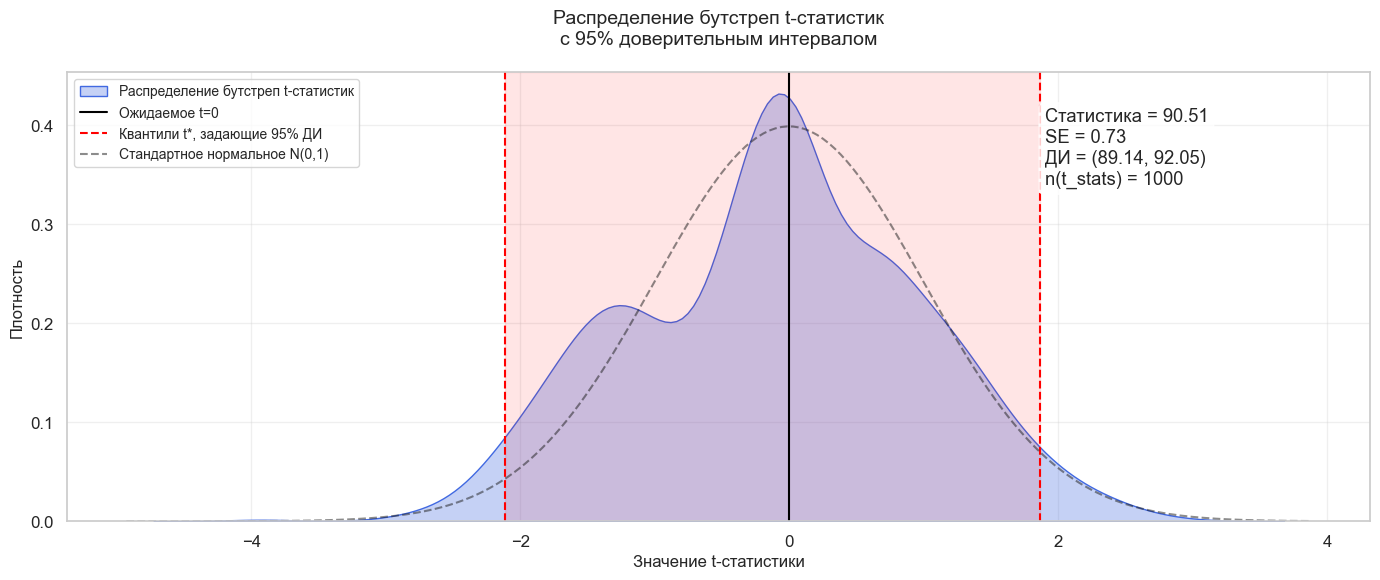


Сравнение с обычным бутстрепом (percentile method):


Обычный бутстреп 95% ДИ: (89.09, 91.92)
Ширина интервала: 2.83


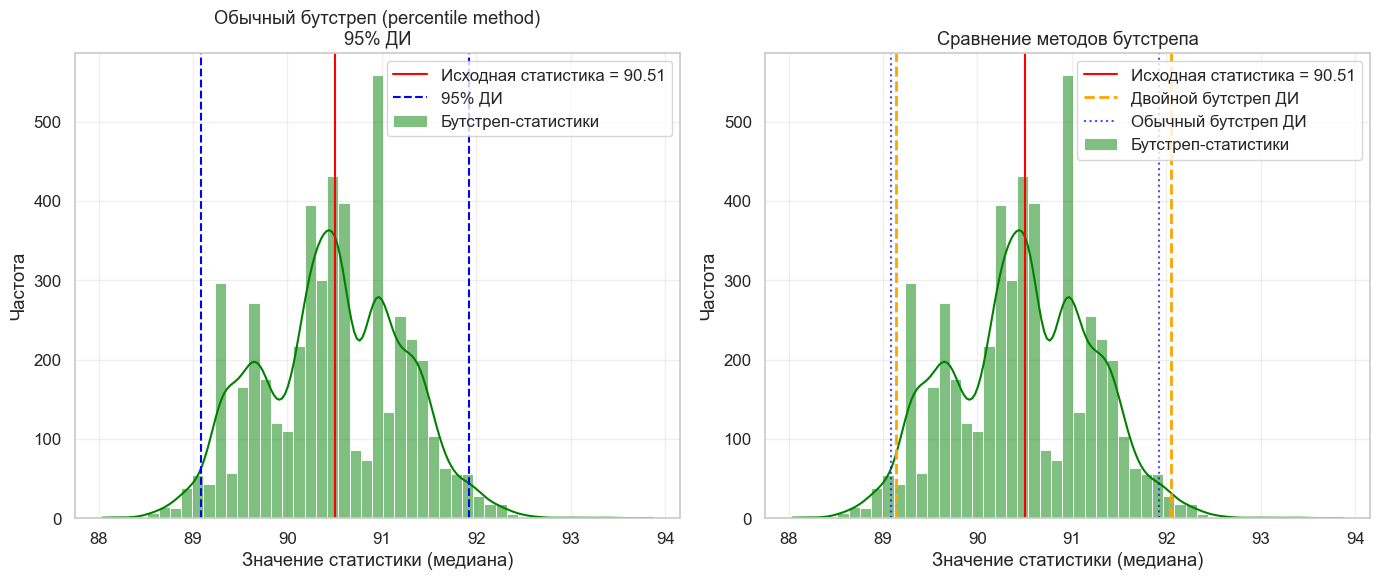

In [16]:
# Настройки
np.random.seed(42)  # Для воспроизводимости
n = 1000            # Исходный размер выборки
B_se = 5000         # Число бутстреп-выборок для оценки se_hat по исходной выборке
B1 = 1000           # Число внешних бутстреп-выборок
B2 = 200            # Число внутренних бутстреп-выборок (для оценки SE*)
alpha = 0.05        # Уровень значимости
confidence_level = int((1 - alpha) * 100)

# Генерация данных
true_mean, true_std = 90, 20
values = np.random.normal(true_mean, true_std, n)

# Точечная оценка
def calculate_statistic(data: np.ndarray, axis: int | None = None) -> float | np.ndarray:
    """Возвращает медиану выборки как статистику интереса (axis=1 — по строкам матрицы выборок)."""
    return np.median(data, axis=axis)

S_hat = calculate_statistic(values)  # Исходная статистика

# 1. Оценка стандартной ошибки se_hat с помощью внутреннего бутстрепа
print("Оценка стандартной ошибки se_hat...")
se_hat_bootstraps = []
for _ in tqdm(range(B_se), desc="Бутстреп для se_hat"):
    X_boot = np.random.choice(values, size=n, replace=True)
    se_hat_bootstraps.append(calculate_statistic(X_boot))

se_hat = np.std(se_hat_bootstraps, ddof=1)
print(f"Оценённая стандартная ошибка (se_hat): {se_hat:.2f}")

# 2. Процедура двойного бутстрепа
t_stats = []  # Бутстреп t-статистики

for i in tqdm(range(B1), desc="Внешний бутстреп"):

    # 1. Генерируем внешнюю бутстреп-выборку X*
    X_star = np.random.choice(values, size=n, replace=True)

    # 2. Считаем статистику S* для внешней выборки
    S_star = calculate_statistic(X_star)

    # 3. Внутренний бутстреп для оценки SE*
    # Генерируем сразу матрицу из B2 внутренних выборок X** (одна строка — одна выборка):
    # так цикл из B2 шагов заменяется одной векторной операцией
    X_double_star = X_star[np.random.randint(0, n, size=(B2, n))]
    S_double_star = calculate_statistic(X_double_star, axis=1)

    # 4. Вычисляем SE*
    se_star = np.std(S_double_star, ddof=1)

    # 5. Вычисляем t-статистику, если SE* > 0
    if se_star > 1e-8:  # Избегаем деления на ноль
        t_stat = (S_star - S_hat) / se_star
        t_stats.append(t_stat)

# Отбрасываем некорректные t-статистики
t_stats = np.array(t_stats)
t_stats = t_stats[~np.isnan(t_stats) & ~np.isinf(t_stats)]

# Расчёт доверительного интервала
t_lower = np.quantile(t_stats, alpha/2)
t_upper = np.quantile(t_stats, 1 - alpha/2)

# Используем квантили из распределения t-статистик для построения ДИ
ci_lower = S_hat - t_upper * se_hat
ci_upper = S_hat - t_lower * se_hat

# Вывод результатов
print(f"\n{' Результаты двойного бутстрепа ':=^60}")
print(f"Исходная статистика (S_hat): {S_hat:.2f}")
print(f"Оценённая стандартная ошибка (se_hat): {se_hat:.2f}")
print(f"Количество t-статистик: {len(t_stats)}")
print(f"{confidence_level}% доверительный интервал: ({ci_lower:.2f}, {ci_upper:.2f})")
print(f"Ширина интервала: {ci_upper - ci_lower:.2f}")
print("=" * 60)

# 3. Визуализация
plt.figure(figsize=(14, 6))

# 1. График распределения бутстреп t-статистик
sns.kdeplot(t_stats, color='royalblue', fill=True, alpha=0.3,
            label='Распределение бутстреп t-статистик')

# 2. Добавляем опорные линии
plt.axvline(0, color='black', linestyle='-', label='Ожидаемое t=0')
plt.axvline(t_lower, color='red', linestyle='--',
            label=f'Квантили t*, задающие {confidence_level}% ДИ')
plt.axvline(t_upper, color='red', linestyle='--')

# 3. Подсвечиваем доверительный интервал
plt.axvspan(t_lower, t_upper, color='red', alpha=0.1)

# 4. Добавляем теоретическую нормаль для сравнения
x = np.linspace(np.min(t_stats) - 1, np.max(t_stats) + 1, 200)
plt.plot(x, stats.norm.pdf(x, 0, 1), 'k--', alpha=0.5,
         label='Стандартное нормальное N(0,1)')

plt.title('Распределение бутстреп t-статистик\n'
          f'с {confidence_level}% доверительным интервалом',
          fontsize=14, pad=20)
plt.xlabel('Значение t-статистики', fontsize=12)
plt.ylabel('Плотность', fontsize=12)
plt.legend(fontsize=10, frameon=True)

# Добавляем блок со статистиками
stats_text = (f"Статистика = {S_hat:.2f}\n"
              f"SE = {se_hat:.2f}\n"
              f"ДИ = ({ci_lower:.2f}, {ci_upper:.2f})\n"
              f"n(t_stats) = {len(t_stats)}")
plt.annotate(stats_text, xy=(0.75, 0.75), xycoords='axes fraction',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

# Дополнительная визуализация: сравнение с обычным бутстрепом
print("\n" + "="*60)
print("Сравнение с обычным бутстрепом (percentile method):")

# Обычный бутстреп (percentile method)
bootstrap_stats = []
for _ in range(B_se):
    X_boot = np.random.choice(values, size=n, replace=True)
    bootstrap_stats.append(calculate_statistic(X_boot))

bootstrap_stats = np.array(bootstrap_stats)
ci_bootstrap_lower = np.quantile(bootstrap_stats, alpha/2)
ci_bootstrap_upper = np.quantile(bootstrap_stats, 1 - alpha/2)

print(f"Обычный бутстреп {confidence_level}% ДИ: ({ci_bootstrap_lower:.2f}, {ci_bootstrap_upper:.2f})")
print(f"Ширина интервала: {ci_bootstrap_upper - ci_bootstrap_lower:.2f}")

# Визуализация сравнения
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(bootstrap_stats, kde=True, color='green', alpha=0.5, label='Бутстреп-статистики')
plt.axvline(S_hat, color='red', linestyle='-', label=f'Исходная статистика = {S_hat:.2f}')
plt.axvline(ci_bootstrap_lower, color='blue', linestyle='--', label=f'{confidence_level}% ДИ')
plt.axvline(ci_bootstrap_upper, color='blue', linestyle='--')
plt.title(f'Обычный бутстреп (percentile method)\n{confidence_level}% ДИ')
plt.xlabel('Значение статистики (медиана)')
plt.ylabel('Частота')
plt.legend()

plt.subplot(1, 2, 2)
sns.histplot(bootstrap_stats, kde=True, color='green', alpha=0.5, label='Бутстреп-статистики')
plt.axvline(S_hat, color='red', linestyle='-', label=f'Исходная статистика = {S_hat:.2f}')
plt.axvline(ci_lower, color='orange', linestyle='--', label='Двойной бутстреп ДИ', linewidth=2)
plt.axvline(ci_upper, color='orange', linestyle='--', linewidth=2)
plt.axvline(ci_bootstrap_lower, color='blue', linestyle=':', label='Обычный бутстреп ДИ', alpha=0.7)
plt.axvline(ci_bootstrap_upper, color='blue', linestyle=':', alpha=0.7)
plt.title('Сравнение методов бутстрепа')
plt.xlabel('Значение статистики (медиана)')
plt.ylabel('Частота')
plt.legend()

plt.tight_layout()
plt.show()

### Парный Бутстреп (Paired Bootstrap)

**Парный бутстреп** — это вариант бутстрепа, который применяется в моделях, где наблюдения состоят из пар связанных значений, например, в задачах регрессии, где каждая строка данных включает зависимую переменную $Y_i$ и набор независимых переменных $X_i$. Особенностью парного бутстрепа является то, что при генерации бутстреп-выборок всегда выбираются пары $(Y_i, X_i)$ целиком, сохраняя исходную взаимосвязь между ними.

**Для чего используется:** Парный бутстреп особенно полезен, когда нужно построить доверительные интервалы для коэффициентов регрессии или других статистик, зависящих от взаимосвязи между переменными. Он сохраняет связь между $Y$ и $X$, которая разрушилась бы, если ресэмплировать столбцы по отдельности.

**Преимущества и Недостатки:**
* **Сохранение структуры данных:** Сохраняет зависимость между $Y$ и $X$ в бутстреп-выборках, что важно для корректной оценки параметров моделей, где такая зависимость является ключевой.
* **Устойчивость к гетероскедастичности:** Парный бутстреп не предполагает одинаковую дисперсию ошибок и даёт корректные ДИ при гетероскедастичности (мы проверим это в следующем разделе). Этим он отличается от бутстрепа остатков, который перемешивает остатки между наблюдениями.
* **Случайные предикторы:** Метод рассматривает $X$ как случайные, поэтому в бутстреп-выборках значения $X$ меняются. На малых выборках редкие значения $X$ могут не попасть в выборку, и оценки становятся нестабильными.

**Алгоритм:**

1. Исходные данные:

    Имеется $n$ пар наблюдений $(Y_1, X_1), \ldots, (Y_n, X_n)$, где $Y_i$ — зависимая переменная, а $X_i$ — вектор независимых переменных для $i$-го наблюдения.

2. Генерация бутстреп-выборки:

    Повторить $B$ раз:
   * Случайно выбрать $n$ пар $(Y_j, X_j)$ из исходных $n$ пар с возвращением. Таким образом, формируется бутстреп-выборка $\left[ (Y_1^*, X_1^*), \ldots, (Y_n^*, X_n^*) \right]$. Некоторые исходные пары могут быть выбраны несколько раз, другие — ни разу.

   * Вычисление статистики: Для каждой бутстреп-выборки оценить интересующую статистику (например, коэффициенты регрессии $\hat{\beta}^*$).

3. Построение доверительного интервала:

    Используя собранные $B$ значений статистики (например, $\hat{\beta}^*_1, \ldots, \hat{\beta}^*_B$), можно построить перцентильный доверительный интервал, аналогично наивному бутстрепу. Для $100 \times (1-\alpha)\%$ ДИ:

$$
\text{ДИ} = \left[ \hat{\beta}^*_{(\alpha/2 \cdot B)} \text{ ; } \hat{\beta}^*_{( (1-\alpha/2) \cdot B )} \right]
$$


========= Результаты бутстреп-регрессии ==========
Истинный коэффициент наклона: 2.00
Оценённый коэффициент наклона: 1.97
Перцентильный бутстреп 95% ДИ: (1.93, 2.01)


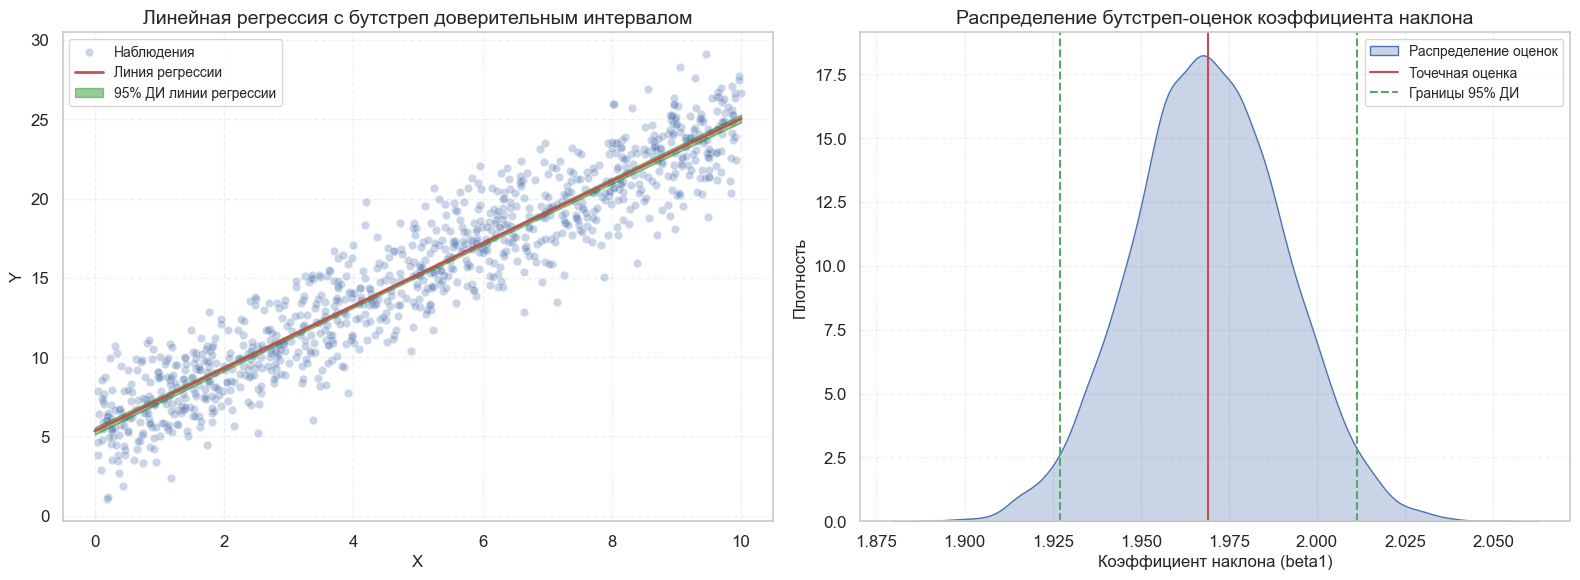

In [17]:
# Настройки
np.random.seed(42)
n = 1000
true_slope = 2
true_intercept = 5
noise_std = 2

# Генерация данных
X_orig = np.random.rand(n, 1) * 10
Y_orig = true_slope * X_orig + true_intercept + np.random.normal(0, noise_std, (n, 1))
data = pd.DataFrame({'X': X_orig.flatten(), 'Y': Y_orig.flatten()})

# 3. Точечные оценки (statsmodels)
X_sm = sm.add_constant(X_orig)
model = sm.OLS(Y_orig, X_sm).fit()
beta1_estimate = model.params[1]
intercept_estimate = model.params[0]

# Настройка бутстрепа
B = 10000
alpha = 0.05
bootstrap_intercept = np.zeros(B)
bootstrap_beta1 = np.zeros(B)
X_flat, Y_flat = X_orig.flatten(), Y_orig.flatten()

# Бутстреп-выборки: пары (X, Y) выбираются целиком, с общими индексами
for i in tqdm(range(B)):
    idx = np.random.randint(0, n, n)
    bootstrap_beta1[i], bootstrap_intercept[i] = np.polyfit(X_flat[idx], Y_flat[idx], deg=1)

# Перцентильный доверительный интервал
percentile_ci = np.percentile(bootstrap_beta1, [2.5, 97.5])


# Результаты
print(f"\n{' Результаты бутстреп-регрессии ':=^50}")
print(f"Истинный коэффициент наклона: {true_slope:.2f}")
print(f"Оценённый коэффициент наклона: {beta1_estimate:.2f}")
print(f"Перцентильный бутстреп 95% ДИ: ({percentile_ci[0]:.2f}, {percentile_ci[1]:.2f})")
print("=" * 50)

# Визуализация

plt.figure(figsize=(16, 6))

# Левый график: линия регрессии с бутстреп-ДИ
plt.subplot(1, 2, 1)
sns.scatterplot(x='X', y='Y', data=data, alpha=0.3, label='Наблюдения')

x_vals = np.linspace(0, 10, 100)
y_pred = intercept_estimate + beta1_estimate * x_vals
plt.plot(x_vals, y_pred, 'r-', linewidth=2, label='Линия регрессии')

# Перцентильный бутстреп-ДИ для линии регрессии: в каждой точке x берём квантили
# предсказаний всех бутстреп-моделей, поэтому учитываются и наклон, и свободный член
y_boot = bootstrap_intercept[:, None] + bootstrap_beta1[:, None] * x_vals
y_lower, y_upper = np.percentile(y_boot, [2.5, 97.5], axis=0)
plt.fill_between(x_vals, y_lower, y_upper, color='green', alpha=0.4,
                 label='95% ДИ линии регрессии')

plt.title('Линейная регрессия с бутстреп доверительным интервалом', fontsize=14)
plt.xlabel('X', fontsize=12)
plt.ylabel('Y', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)

# Правый график: распределение бутстреп-оценок
plt.subplot(1, 2, 2)
sns.kdeplot(bootstrap_beta1, fill=True, alpha=0.3,
            label='Распределение оценок')

plt.axvline(beta1_estimate, color='r', linestyle='-',
            label='Точечная оценка')
plt.axvline(percentile_ci[0], color='g', linestyle='--',
            label='Границы 95% ДИ')
plt.axvline(percentile_ci[1], color='g', linestyle='--')

plt.title('Распределение бутстреп-оценок коэффициента наклона', fontsize=14)
plt.xlabel('Коэффициент наклона (beta1)', fontsize=12)
plt.ylabel('Плотность', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### Дикий Бутстреп (Wild Bootstrap)

**Дикий бутстреп** — это специализированный вариант бутстрепа, в котором значения предикторов остаются фиксированными, а случайность вносится только через ошибки зависимой переменной. Он особенно полезен в условиях гетероскедастичности, то есть когда дисперсия ошибок не является постоянной для всех наблюдений.

**Для чего используется**: Дикий бутстреп позволяет корректно оценить неопределенность в регрессионных моделях, когда стандартные допущения о гомоскедастичности нарушены. Он фиксирует значения предикторов ($X_i$) и генерирует новые зависимые переменные ($Y^*_i$) путем добавления к предсказанным значениям $\hat{Y}_i$ масштабированных и случайным образом измененных остатков $\hat{u}_i$. Это обеспечивает более точные доверительные интервалы и проверки гипотез, чем парный бутстреп в условиях гетероскедастичности.

**Преимущества и Недостатки:**

* **Устойчивость к гетероскедастичности:** Главное преимущество — корректная работа при гетероскедастичности и ненормальных ошибках.
* **Фиксированные предикторы:** Значения $X$ не ресэмплируются, поэтому в бутстреп-выборках не пропадают редкие значения предикторов. При этом метод не учитывает автокорреляцию ошибок, так что для временных рядов нужны блочные варианты.
* **Сложность реализации:** Масштабирование остатков и выбор правильных весов могут быть нетривиальными.

**Алгоритм:**

1. Оценить исходную модель:

    По исходным данным $(Y_i, X_i)$ оценить регрессионную модель (например, $Y_i = \beta X_i + u_i$) и получить оценки коэффициентов $\hat{\beta}$ и остатки (residuals) $\hat{u}_i = Y_i - \hat{Y}_i = Y_i - \hat{\beta}X_i$.

2. Масштабировать остатки:

    Остатки $\hat{u}_i$ могут иметь разную дисперсию, даже если истинные ошибки $u_i$ гомоскедастичны, особенно в линейной регрессии. Чтобы скорректировать это, остатки масштабируются на диагональные элементы матрицы $H = X(X^T X)^{-1} X^T$:
  
  $$ \hat{u}_{i}^\text{scaled} = \frac{\hat{u}_i}{\sqrt{1 - H_{i}}}
  \quad \text{ где } H_{i} \text{ — i-й диагональный элемент матрицы H}
  $$
  
3. Генерировать бутстреп-выборку:
    
    Повторить $B$ раз:
  
    * Сгенерировать случайные веса $v_i$ для каждого масштабированного остатка. Эти веса должны иметь нулевое математическое ожидание и единичную дисперсию. Часто используются распределения, такие как:
      *  ± 1 с вероятностью 0.5 (распределение Радермахера).
      * Стандартное нормальное распределение $N(0,1)$.
    
    * Создать новую зависимую переменную $Y_i^*$ для каждой бутстреп-выборки, используя предсказанные значения из исходной модели $\hat{Y}_i$ и масштабированные остатки, умноженные на случайные веса:
  
  $$
  Y_i^* = \hat{Y}_i + \hat{u}_i^\text{scaled} \cdot v_i
  $$

4. Оценить модель на бутстреп-выборке:

    Оценить регрессионную модель на сгенерированных данных $(X_i, Y_i^*)$ для получения бутстреп-оценок коэффициентов $\hat{\beta}^*$.

5. Построить доверительный интервал или проверить гипотезу:
  
    Используя собранные $B$ значений $\hat{\beta}^*$, можно построить перцентильный доверительный интервал. Для проверки гипотез о равенстве коэффициентов нулю, можно посмотреть на распределение бутстреп-коэффициентов или F-статистики, полученных в предположении нулевой гипотезы.


============== Результаты регрессии ==============
Истинный коэффициент наклона: 2.00
Оценённый коэффициент наклона: 2.03
Аналитический 95% ДИ (OLS): (1.777, 2.277)
«Дикий» бутстреп 95% ДИ:    (1.706, 2.356)


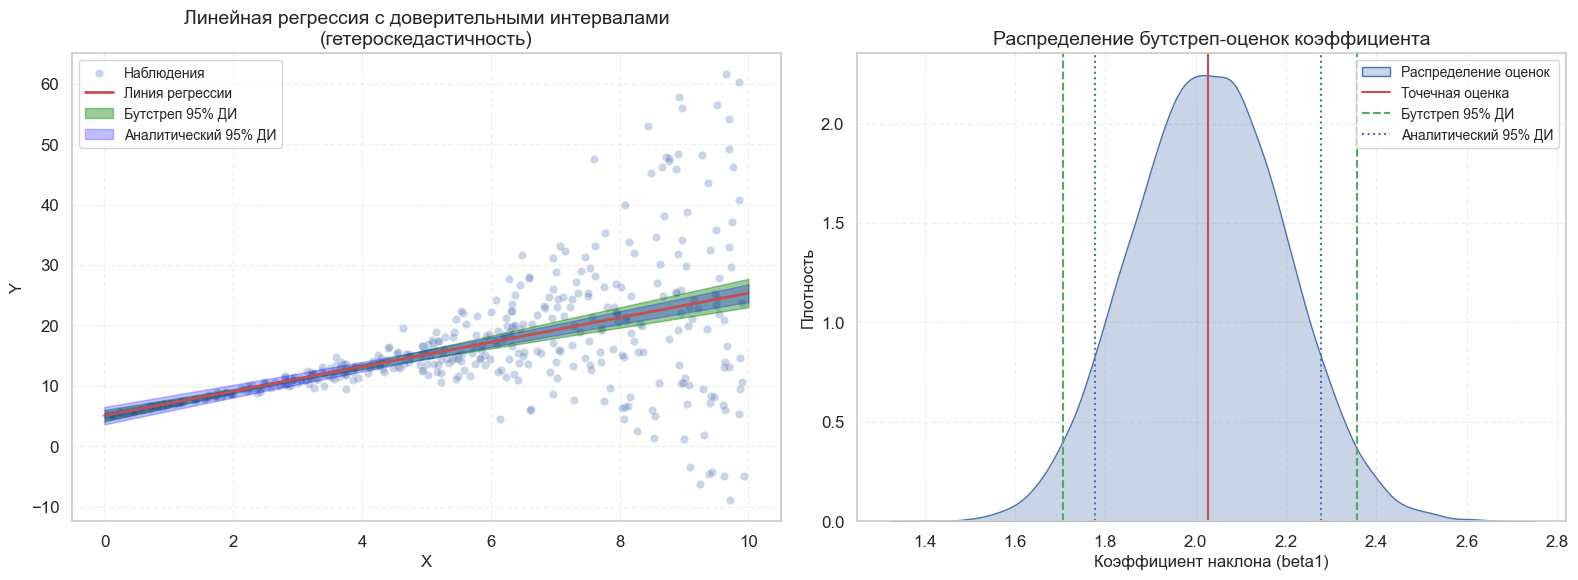

In [18]:
# Настройки

np.random.seed(42)
n = 500
true_slope = 2
true_intercept = 5

# 2. Генерация данных с гетероскедастичностью: разброс ошибок быстро растёт вместе с X

X_orig = np.random.rand(n, 1) * 10
errors = np.random.normal(0, 0.02 * X_orig**3 + 0.1)
Y_orig = true_slope * X_orig + true_intercept + errors

data = pd.DataFrame({'X': X_orig.flatten(), 'Y': Y_orig.flatten()})

# 3. Оценка исходной модели (statsmodels)
X_sm = sm.add_constant(X_orig)
model = sm.OLS(Y_orig, X_sm).fit()
beta1_estimate = model.params[1]
intercept_estimate = model.params[0]
residuals = model.resid

# Матрица шляп и масштабированные остатки
XTX_inv = np.linalg.inv(X_sm.T @ X_sm)
h_ii = np.sum((X_sm @ XTX_inv) * X_sm, axis=1)
scaled_residuals = residuals / np.sqrt(1 - h_ii)

# Настройка «дикого» бутстрепа
B = 10000
alpha = 0.05
bootstrap_intercept = np.zeros(B)
bootstrap_beta1 = np.zeros(B)
Y_hat = model.predict(X_sm)
ols_projection = XTX_inv @ X_sm.T  # beta = ols_projection @ Y: не нужно обучать модель заново

# 5. Процедура «дикого» бутстрепа
for i in tqdm(range(B), desc="Прогресс «дикого» бутстрепа"):
    # Веса Радермахера
    v_i = np.random.choice([-1, 1], n)

    # Формируем бутстреп-выборку
    Y_star = Y_hat + scaled_residuals * v_i

    # Обучаем бутстреп-модель
    bootstrap_intercept[i], bootstrap_beta1[i] = ols_projection @ Y_star

# Доверительные интервалы
# Перцентильный ДИ
percentile_ci = np.percentile(bootstrap_beta1, [2.5, 97.5])

# Аналитический ДИ из statsmodels
analytical_ci = model.conf_int(alpha=0.05)[1]


# Результаты
print(f"\n{' Результаты регрессии ':=^50}")
print(f"Истинный коэффициент наклона: {true_slope:.2f}")
print(f"Оценённый коэффициент наклона: {beta1_estimate:.2f}")
print(f"Аналитический 95% ДИ (OLS): ({analytical_ci[0]:.3f}, {analytical_ci[1]:.3f})")
print(f"«Дикий» бутстреп 95% ДИ:    ({percentile_ci[0]:.3f}, {percentile_ci[1]:.3f})")
print("=" * 50)


# Визуализация
plt.figure(figsize=(16, 6))

# Левый график: линия регрессии с доверительными интервалами
plt.subplot(1, 2, 1)
sns.scatterplot(x='X', y='Y', data=data, alpha=0.3, label='Наблюдения')

x_vals = np.linspace(0, 10, 100)
y_pred = intercept_estimate + beta1_estimate * x_vals
plt.plot(x_vals, y_pred, 'r-', linewidth=2, label='Линия регрессии')

# Бутстреп-ДИ линии регрессии: квантили предсказаний бутстреп-моделей в каждой точке x
y_boot = bootstrap_intercept[:, None] + bootstrap_beta1[:, None] * x_vals
y_lower, y_upper = np.percentile(y_boot, [2.5, 97.5], axis=0)
plt.fill_between(x_vals, y_lower, y_upper, color='green', alpha=0.4, label='Бутстреп 95% ДИ')

# Аналитический ДИ линии регрессии
pred_ci = model.get_prediction(sm.add_constant(x_vals)).conf_int(alpha=0.05)
plt.fill_between(x_vals, pred_ci[:, 0], pred_ci[:, 1], color='blue', alpha=0.25, label='Аналитический 95% ДИ')

plt.title('Линейная регрессия с доверительными интервалами\n(гетероскедастичность)', fontsize=14)
plt.xlabel('X', fontsize=12)
plt.ylabel('Y', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)

# Правый график: распределение бутстреп-оценок
plt.subplot(1, 2, 2)
sns.kdeplot(bootstrap_beta1, fill=True, alpha=0.3,
            label='Распределение оценок')

plt.axvline(beta1_estimate, color='r', linestyle='-',
            label='Точечная оценка')
plt.axvline(percentile_ci[0], color='g', linestyle='--',
            label='Бутстреп 95% ДИ')
plt.axvline(percentile_ci[1], color='g', linestyle='--')
plt.axvline(analytical_ci[0], color='b', linestyle=':',
            label='Аналитический 95% ДИ')
plt.axvline(analytical_ci[1], color='b', linestyle=':')

plt.title('Распределение бутстреп-оценок коэффициента', fontsize=14)
plt.xlabel('Коэффициент наклона (beta1)', fontsize=12)
plt.ylabel('Плотность', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Аналитический интервал заметно уже бутстрепного: формула OLS предполагает одинаковую дисперсию ошибок и недооценивает разброс наклона. Один пример ничего не доказывает, поэтому проверим **покрытие**: повторим эксперимент много раз и посчитаем, как часто каждый 95% ДИ накрывает истинный наклон. Заодно сравним с парным бутстрепом и бутстрепом остатков, где остатки перемешиваются между наблюдениями.

In [19]:
rng = np.random.default_rng(42)
n, R, B = 500, 1000, 400
hits = dict.fromkeys(['OLS, аналитический', 'Парный бутстреп', 'Бутстреп остатков', 'Дикий бутстреп'], 0)

for _ in tqdm(range(R), desc="Проверка покрытия"):
    X = rng.uniform(0, 10, n)
    Y = true_intercept + true_slope * X + rng.normal(0, 0.02 * X**3 + 0.1)

    Z = np.column_stack([np.ones(n), X])
    XTX_inv = np.linalg.inv(Z.T @ Z)
    slope_weights = (XTX_inv @ Z.T)[1]             # наклон = slope_weights @ Y
    slope = slope_weights @ Y
    resid = Y - Z @ (XTX_inv @ Z.T @ Y)
    h = np.sum((Z @ XTX_inv) * Z, axis=1)

    # Аналитический ДИ
    se = np.sqrt(XTX_inv[1, 1] * (resid @ resid) / (n - 2))
    z = stats.t.ppf(0.975, n - 2)
    hits['OLS, аналитический'] += abs(slope - true_slope) <= z * se

    # Парный бутстреп: ресэмплируем строки целиком
    idx = rng.integers(0, n, (B, n))
    X_b, Y_b = X[idx], Y[idx]
    X_c = X_b - X_b.mean(axis=1, keepdims=True)
    pairs = (X_c * Y_b).sum(axis=1) / (X_c**2).sum(axis=1)

    # Бутстреп остатков: остатки перемешиваются между наблюдениями
    residual = slope + resid[rng.integers(0, n, (B, n))] @ slope_weights

    # Дикий бутстреп: остаток остаётся при своём наблюдении, меняется только знак
    signs = rng.choice([-1.0, 1.0], (B, n))
    wild = slope + (signs * resid / np.sqrt(1 - h)) @ slope_weights

    for name, boot in [('Парный бутстреп', pairs), ('Бутстреп остатков', residual), ('Дикий бутстреп', wild)]:
        left, right = np.percentile(boot, [2.5, 97.5])
        hits[name] += left <= true_slope <= right

print(f"Покрытие 95% ДИ для наклона ({R} экспериментов):")
for name, count in hits.items():
    print(f"• {name}: {count / R:.3f}")

Покрытие 95% ДИ для наклона (1000 экспериментов):
• OLS, аналитический: 0.857
• Парный бутстреп: 0.943
• Бутстреп остатков: 0.853
• Дикий бутстреп: 0.945


Формула OLS и бутстреп остатков предполагают, что все ошибки распределены одинаково, и при гетероскедастичности дают покрытие заметно ниже 95%. Парный и дикий бутстреп сохраняют связь размера ошибки с $X$, поэтому их покрытие близко к номинальному.

### Пуассоновский Бутстреп (Poisson Bootstrap)

**Пуассоновский бутстреп** — это специальный вид бутстрепа, разработанный для работы с очень большими объемами данных (Big Data) или с потоковыми данными, когда невозможно загрузить всю выборку в память или многократно сэмплировать её с возвращением. В таких сценариях традиционные методы бутстрепа становятся вычислительно слишком затратными.

**Для чего используется:** Ключевая идея пуассоновского бутстрепа заключается в том, что вместо явного создания бутстреп-выборок путем выбора $n$ элементов с возвращением из $n$, мы определяем, сколько раз каждое исходное наблюдение попадет в бутстреп-выборку. Это количество раз для каждого наблюдения $i$ генерируется из распределения Пуассона с параметром $\lambda=1$.

**Преимущества и Недостатки:**
* **Эффективность для Big Data и потоковых данных:** Главное преимущество — возможность работать с данными, которые не помещаются в память, или с потоковыми данными.
* **Отсутствие явного ресэмплинга:** Нет необходимости создавать физические копии данных, что экономит память и время.
* **Приближение:** Это аппроксимация стандартного бутстрепа, и хотя она точна для больших N, для малых выборок может быть менее точной.

**Алгоритм:**
1. Связь с биномиальным распределением:

    В стандартном бутстрепе количество раз, которое каждое конкретное наблюдение попадает в бутстреп-выборку размера $n$, следует биномиальному распределению $Bin(n, p=1/n)$. При очень большом $n$, это биномиальное распределение хорошо аппроксимируется распределением Пуассона с параметром $\lambda = n \cdot (1/n) = 1$.

2. Генерация весов:

    Для каждого исходного наблюдения $X_i$ (или пары $(Y_i, X_i)$) генерируется случайное целое число $k_i$ из распределения Пуассона $\text{Pois}(1)$. Это число $k_i$ представляет собой "вес" или количество копий $X_i$, которое войдет в текущую бутстреп-выборку.

3. Формирование бутстреп-статистики:

    Вместо создания новой выборки, статистика вычисляется напрямую, используя взвешенные исходные данные. То есть, если мы хотим оценить сумму, мы суммируем $X_i \cdot k_i$. Если хотим оценить среднее, то $\sum (X_i \cdot k_i) / \sum k_i$.

4. Повторение:

    Шаги 2 и 3 повторяются $B$ раз, чтобы собрать распределение статистики.

5. Построение доверительного интервала:

    Аналогично наивному бутстрепу, можно использовать перцентильный метод на собранных бутстреп-значениях статистики.


=================== Результаты ===================
Истинная медиана: 25.42 мин
Оценка медианы:   25.44 мин
Пуассоновский 95% ДИ: (25.38, 25.50)


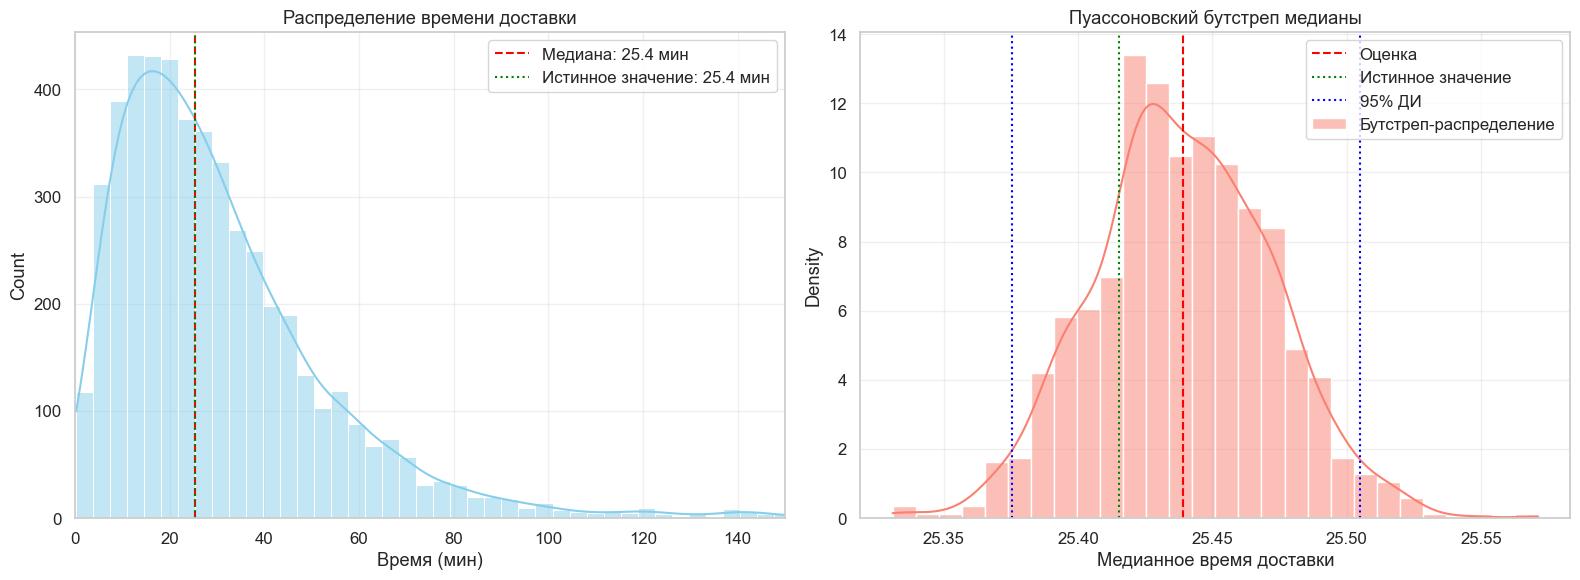

In [20]:
# Настройки

rng = np.random.default_rng(42)
n_stream     = 500_000


# Генерация данных

delivery_times = rng.gamma(shape=2, scale=15, size=n_stream)
outliers       = rng.uniform(120, 180, size=int(n_stream * 0.01))
delivery_times = np.concatenate([delivery_times, outliers])

sample_df = pd.DataFrame({'delivery_time': rng.choice(delivery_times, size=5000, replace=False)})

# Истинная медиана смеси: 100/101 — Gamma(2, 15), 1/101 — выбросы U(120, 180), которые все правее медианы
true_median = stats.gamma.ppf(0.5 * 101 / 100, a=2, scale=15)


# Статистики
def weighted_median(sorted_data: np.ndarray, weights: np.ndarray) -> float:
    """Вычисляет взвешенную медиану заранее отсортированных данных.

    Args:
        sorted_data: Наблюдения, отсортированные по возрастанию.
        weights: Вес каждого наблюдения.

    Returns:
        Значение взвешенной медианы.
    """
    cumsum = np.cumsum(weights)
    idx = np.searchsorted(cumsum, 0.5 * cumsum[-1], side="left")
    return float(sorted_data[idx])

original_median = np.median(delivery_times)
sorted_times = np.sort(delivery_times)  # сортируем один раз, а не на каждой итерации

# Параметры бутстрепа
B      = 1000
alpha  = 0.05
ci_pct = (alpha / 2 * 100, (1 - alpha / 2) * 100)
ci_lvl = int((1 - alpha) * 100)

bootstrap_medians = np.empty(B)

# ---------------------- Пуассоновский бутстреп ----------------------
for i in tqdm(range(B), desc="Пуассоновский бутстреп"):
    weights = rng.poisson(1, size=sorted_times.size)
    bootstrap_medians[i] = weighted_median(sorted_times, weights)

# Доверительные интервалы
ci_lower, ci_upper = np.percentile(bootstrap_medians, ci_pct)

# Результаты
print(f"\n{' Результаты ':=^50}")
print(f"Истинная медиана: {true_median:.2f} мин")
print(f"Оценка медианы:   {original_median:.2f} мин")
print(f"Пуассоновский {ci_lvl}% ДИ: ({ci_lower:.2f}, {ci_upper:.2f})")
print("=" * 50)


# Визуализация

plt.figure(figsize=(16, 6))

# График 1
plt.subplot(1, 2, 1)
sns.histplot(sample_df, x='delivery_time', bins=50,
             kde=True, color='skyblue')
plt.axvline(original_median, color='red', linestyle='--',
            label=f'Медиана: {original_median:.1f} мин')
plt.axvline(true_median, color='green', linestyle=':',
            label=f'Истинное значение: {true_median:.1f} мин')
plt.title('Распределение времени доставки')
plt.xlabel('Время (мин)')
plt.xlim(0, 150)
plt.legend()

# График 2
plt.subplot(1, 2, 2)
sns.histplot(bootstrap_medians, kde=True, color='salmon',
             stat='density', label='Бутстреп-распределение')
plt.axvline(original_median, color='red', linestyle='--', label='Оценка')
plt.axvline(true_median, color='green', linestyle=':', label='Истинное значение')
plt.axvline(ci_lower, color='blue', linestyle=':', label=f'{ci_lvl}% ДИ')
plt.axvline(ci_upper, color='blue', linestyle=':')
plt.title('Пуассоновский бутстреп медианы')
plt.xlabel('Медианное время доставки')
plt.legend()

plt.tight_layout()
plt.show()

### Заключение

Бутстреп является крайне универсальным и мощным методом в статистике, позволяющим исследовать свойства распределений произвольных статистик, строить доверительные интервалы и проверять гипотезы даже для нетривиальных метрик, для которых нет удобных аналитических формул. Его способность адаптироваться к различным условиям данных (i.i.d., парные данные, гетероскедастичность, потоковые данные) делает его незаменимым инструментом для аналитиков данных и исследователей. Однако важно помнить о его вычислительной трудоёмкости и необходимости учитывать природу данных при выборе конкретного типа бутстрепа.